In [1]:
import os
os.environ["PATH_TO_POSYDON"] = "/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages"
print(os.getenv("PATH_TO_POSYDON"))
print(os.getenv("PATH_TO_POSYDON_DATA"))

/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages
/srv/astro/projects/posydon/data_sync_staging/POSYDON_datasets/latest_stable/


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 
from IPython.display import display

from scipy.optimize import newton

import posydon
import posydon.utils.constants as const
from posydon.popsyn.synthetic_population import Population
from posydon.utils.common_functions import roche_lobe_radius, orbital_separation_from_period
from posydon.utils.posydonwarning import Pwarn, POSYDONWarning
import warnings

# Convert POSYDON warnings to exceptions to stop execution on warnings
warnings.filterwarnings('error', category=POSYDONWarning)

print("Posydon version: ", posydon.__version__)

Posydon version:  2.2.2


In [2]:
%load_ext autoreload
%autoreload 2

class color:
    # Reset
    END = '\033[0m'

    # Styles
    BOLD = '\033[1m'
    DIM = '\033[2m'
    ITALIC = '\033[3m'
    UNDERLINE = '\033[4m'
    REVERSE = '\033[7m'
    STRIKE = '\033[9m'

    # Standard colors
    BLACK = '\033[30m'
    RED = '\033[31m'
    GREEN = '\033[32m'
    YELLOW = '\033[33m'
    BLUE = '\033[34m'
    PURPLE = '\033[35m'
    CYAN = '\033[36m'
    WHITE = '\033[37m'

    # Bright colors
    BRIGHT_BLACK = '\033[90m'
    BRIGHT_RED = '\033[91m'
    BRIGHT_GREEN = '\033[92m'
    BRIGHT_YELLOW = '\033[93m'
    BRIGHT_BLUE = '\033[94m'
    BRIGHT_PURPLE = '\033[95m'
    BRIGHT_CYAN = '\033[96m'
    BRIGHT_WHITE = '\033[97m'

    # Background colors
    BG_RED = '\033[41m'
    BG_GREEN = '\033[42m'
    BG_YELLOW = '\033[43m'
    BG_BLUE = '\033[44m'

print("\n" + color.BOLD + color.BLUE + "This is bold blue text" + color.END)
print(color.ITALIC + color.GREEN + "This is italic green text" + color.END)
print(color.UNDERLINE + color.RED + "This is underlined red text" + color.END)
print(color.STRIKE + color.YELLOW + "This is strikethrough yellow text" + color.END)
print(color.BG_BLUE + color.WHITE + "This is white text on blue background" + color.END)


This is bold blue text
This is italic green text
This is underlined red text
This is strikethrough yellow text
This is white text on blue background


In [6]:
import time
import threading
from IPython.display import display, clear_output

class AnimatedSpinner:
    """
    A simple animated spinner/loading indicator for long-running operations in Jupyter notebooks.
    """
    def __init__(self, message="Processing", animation_type="dots"):
        """
        Parameters
        ----------
        message : str
            The message to display before the animation
        animation_type : str
            Type of animation: 'dots', 'spinner', or 'bounce'
        """
        self.message = message
        self.animation_type = animation_type
        self.running = False
        self.thread = None
        
        # Define animation sequences
        self.animations = {
            'dots': ['   ', '.  ', '.. ', '...'],
            'spinner': ['|', '/', '-', '\\'],
            'bounce': ['⠋', '⠙', '⠹', '⠸', '⠼', '⠴', '⠦', '⠧', '⠇', '⠏'],
            'arrow': ['←', '↖', '↑', '↗', '→', '↘', '↓', '↙']
        }
        
    def _animate(self):
        """Run the animation in a loop."""
        frames = self.animations.get(self.animation_type, self.animations['dots'])
        idx = 0
        while self.running:
            clear_output(wait=True)
            print(f'{self.message} {frames[idx % len(frames)]}', end='')
            idx += 1
            time.sleep(0.2)
    
    def start(self):
        """Start the animation."""
        self.running = True
        self.thread = threading.Thread(target=self._animate)
        self.thread.daemon = True
        self.thread.start()
    
    def stop(self, final_message=None):
        """Stop the animation and clear the line."""
        self.running = False
        if self.thread:
            self.thread.join()
        clear_output(wait=True)
        if final_message:
            print(final_message)

# Test the spinner
print("\nTesting different animation types:\n")

# Test dots
spinner = AnimatedSpinner("Loading data", "dots")
spinner.start()
time.sleep(3)
spinner.stop("✓ Data loaded!")

# Test spinner
spinner = AnimatedSpinner("Processing files", "spinner")
spinner.start()
time.sleep(3)
spinner.stop("✓ Files processed!")

# Test bounce
spinner = AnimatedSpinner("Computing results", "bounce")
spinner.start()
time.sleep(3)
spinner.stop("✓ Results ready!")

print("\n" + color.GREEN + "AnimatedSpinner class is ready to use!" + color.END)

✓ Results ready!

AnimatedSpinner class is ready to use!


In [2]:

def Systems_selection_for_XRB(path_file_h5, filename_out, verbose=True):
    """
    Selects compact-object binaries with non-compact companions and exports the new population.

    Keeps systems that have one compact object (NS/BH) and a companion that is
    neither a compact object nor a massless remnant, and that are not in excluded system states.

    The output file(s) can be later used in create_transient_population() with X-ray binary selection function. 

    Parameters
    ----------
    path_file_h5 : str or list of str
        Path(s) to the input .h5 file(s) containing binary systems.

    filename_out : str or list of str
        Name(s) for the file(s) that will be exported (without the extension).
    verbose : bool, optional
        If True, print detailed information about the process. Default is True.

    Returns
    -------
    None
        The function exports selected systems to .h5 file(s) at the same location as the input file(s),
        named as `filename_out.h5`.

    Examples
    --------
    For a single file:

    >>> Systems_selection_for_XRB('path/1e+00_Zsun_population.h5', 'BHNS_selected')
    File: 1e+00_Zsun_population.h5. Selection stored as path/BHNS_selected.h5
          Number of selected systems: 8000.

    For a list of files:

    >>> files_list = ['path/1e+00_Zsun_population.h5', 'path/1e-01_Zsun_population.h5', 'path/1e-04_Zsun_population.h5']
    >>> filename_out_list = ['NewName1', 'NewName2', 'NewName3']
    >>> Systems_selection_for_XRB(files_list, filename_out_list)
    File: 1e+00_Zsun_population.h5. Selection stored as path/NewName1.h5
          Number of selected systems: 8000.
    File: 1e-01_Zsun_population.h5. Selection stored as path/NewName2.h5
          Number of selected systems: 7543.
    File: 1e-04_Zsun_population.h5. Selection stored as path/NewName3.h5
          Number of selected systems: 12756.

    """
    
    #===== Input file(s) validation =====
    if isinstance(path_file_h5, str):
        if path_file_h5.strip() == "":
            Pwarn("file path must be a non-empty string", category="InappropriateValueWarning")
            return None
        files = [path_file_h5]
    elif isinstance(path_file_h5, list):
        # List of file paths
        if not all(isinstance(f, str) and f.strip() != "" for f in path_file_h5):
            Pwarn("All elements in file list must be non-empty strings", 
                  category="InappropriateValueWarning")
            return None
        files = path_file_h5
    else:
        Pwarn("file must be a string or a list of strings (file paths)", category="InappropriateValueWarning")
        return None
    
    # Check that all files are .h5 files
    if not all(f.endswith('.h5') for f in files):
        Pwarn("All input files must be .h5 files", category="InappropriateValueWarning")
        return None
    
    #===== Output filename(s) validation =====
    if isinstance(filename_out, str):
        if filename_out.strip() == "":
            Pwarn("filename_out must be a non-empty string", category="InappropriateValueWarning")
            return None
        filenames = [filename_out]
    elif isinstance(filename_out, list):
        # List of filenames
        if not all(isinstance(fn, str) and fn.strip() != "" for fn in filename_out):
            Pwarn("All elements in filename_out list must be non-empty strings", 
                  category="InappropriateValueWarning")
            return None
        filenames = filename_out
    else:
        Pwarn("filename_out must be a string or a list of strings", category="InappropriateValueWarning")
        return None
    
    #===== Length consistency check =====
    if len(files) != len(filenames):
        Pwarn(f"Number of input files ({len(files)}) must match number of output filenames ({len(filenames)})", 
              category="InappropriateValueWarning")
        return None
    
    #===== Binaries extraction and export =====
    compact_types = {'NS', 'BH'}
    objects_to_avoid = {'NS', 'BH', 'massless_remnant', 'WD'}  # Avoid double CO, WD, massless remnants companions
    bad_system_states = {'disrupted', 'ERR', 'initial_RLOF'}

    out_fn = []

    for fh5, fn in zip(files, filenames):

        if verbose:
            print(f"\nProcessing file {fh5} in Population() ...")

        tmp_pop = Population(fh5)
        tmp_oneline = tmp_pop.oneline[['state_f', 'S1_state_f', 'S2_state_f', 'event_f']]

        state1, state2, state_sys = tmp_oneline['S1_state_f'], tmp_oneline['S2_state_f'], tmp_oneline['state_f']
        
        mask = (
            (state1.isin(compact_types) & ~state2.isin(objects_to_avoid) & ~state_sys.isin(bad_system_states))
            | (state2.isin(compact_types) & ~state1.isin(objects_to_avoid) & ~state_sys.isin(bad_system_states))
        )
        idx = tmp_oneline.index[mask]

        del tmp_oneline

        # Export the selection to the same directory as the input file
        output_path = os.path.join(os.path.dirname(fh5) or '.', f"{fn}.h5")

        if verbose:
            print(f"Exporting selected systems to {output_path} ...")

        tmp_pop.export_selection(list(idx), output_path, overwrite=True)
        out_fn.append(output_path)

        del tmp_pop
        
        if verbose:
            print(f"Resume: {os.path.basename(fh5)}.\n" 
                  + 8*' ' +"Selection stored as " + "\033[1m" + f"{output_path} \n" 
                  + "\033[0m" + 8*' ' + f"Number of selected systems : {len(idx)}.")

In [7]:
Systems_selection_for_XRB('Population_from_Misra_paper/Default_Pop/1e+00_Zsun_population.h5', 'BHNS_selected')

File: 1e+00_Zsun_population.h5. Selection stored as Population_from_Misra_paper/Default_Pop/BHNS_selected.h5 
      Number of selected systems : 82972.


In [4]:
selection = Population('Population_from_Misra_paper/Default_Pop/BHNS_selected.h5') # Refined
selection2 = Population('Population_from_Misra_paper/Default_Pop/BHNS_only.h5')

In [ ]:
# ONLY IF NOT ALREADY DONE ONCE !!

#selection.calculate_formation_channels(mt_history=True)
#selection2.calculate_formation_channels(mt_history=True)

Formation channels already exist in the parsed population file!
Channels will be overwriten


### Other way to get selection

In [ ]:
Pop1_Misra0 = Population('Default_Pop/1e+00_Zsun_population.h5')

In [ ]:
tmp_oneline = Pop1_Misra0.oneline[['state_f', 'S1_state_f', 'S2_state_f', 'event_f']]

In [ ]:
Compact_types = {'NS','BH'}
Objects_to_avoid = {'NS','BH','massless_remnant', 'WD'} # Avoid double CO, WD, massless remnants companions
bad_systems_states = {'disrupted', 'ERR', 'initial_RLOF'}


state1, state2, state_sys = tmp_oneline['S1_state_f'], tmp_oneline['S2_state_f'], tmp_oneline['state_f']

mask = ((state1.isin(Compact_types) & ~state2.isin(Objects_to_avoid)) 
        & ~state_sys.isin(bad_systems_states)) | ((state2.isin(Compact_types) 
                                                   & ~state1.isin(Objects_to_avoid)) 
                                                   & ~state_sys.isin(bad_systems_states))

tmp_selection = Pop1_Misra0.oneline[list(tmp_oneline[mask].index)]
Pop1_Misra0.export_selection(list(tmp_selection.index), 'BHNS_only.h5')

## 1st way of plotting

In [ ]:
selection_oneline =selection.oneline[:]

In [ ]:
orbital_separation = orbital_separation_from_period(selection_oneline['orbital_period_f'], selection_oneline['S1_mass_f'], selection_oneline['S2_mass_f'])

Donor_RL_f = roche_lobe_radius(selection_oneline['S2_mass_f'].to_numpy(), selection_oneline['S1_mass_f'].to_numpy(), orbital_separation)

mask_be = ((selection_oneline['S2_state_f'] == 'H-rich_Core_H_burning')
            & (selection_oneline['S2_mass_f'] >= 6.0)
            & (selection_oneline['state_f'] == 'detached')
            &  (selection_oneline['S2_surf_avg_omega_div_omega_crit_f'] >= 0.7)
            & (selection_oneline['orbital_period_f'] >= 10.0)
            & (selection_oneline['orbital_period_f'] <= 300.0)
            & (Donor_RL_f <= (100.0 * 10**(selection_oneline['S2_log_R_f'])))
            )

In [ ]:
def Be_XRB_Lx(period):

    Lx = (10.0**35) * 10.0**(4.53 - (1.50 * np.log10(period))) 
    return Lx

Df_Be = selection_oneline[mask_be].copy()

Df_Be['Be_XLF'] = Be_XRB_Lx(selection_oneline.loc[mask_be, 'orbital_period_f'].to_numpy())

In [ ]:
Other_systems = selection_oneline.loc[~selection_oneline.index.isin(Df_Be.index)].copy()

RLO_sys = Other_systems.loc[Other_systems['state_f'] == 'RLO2'].copy()

Wind_sys = Other_systems.loc[Other_systems['state_f'] == 'detached'].copy()

In [6]:
def Eddington_limit(accretor_mass, Donor_surface_H1, eta):
    L_edd = 4.0 * np.pi * const.standard_cgrav * accretor_mass * const.Msun * const.clight /(0.2 * (1.0 + Donor_surface_H1)) # [erg/s]
    Mdot_Edd_gps = L_edd / (eta * const.clight**2) # [g/s]
    return Mdot_Edd_gps, L_edd

def BH_efficiency(spin):
    
     # To control that the spin is in the range that gives the maximal efficiency
    a_star = float(np.clip(spin, -0.998, 0.998))

    #=== Compute efficiency [1]=== 
    
    # Use sign = +1 for spin ≥ 0 (prograde) and -1 otherwise (retrograde)
    sign = 1 if a_star >= 0 else -1

    Z1 = 1 + (1 - a_star**2)**(1/3) * ((1 + a_star)**(1/3) + (1 - a_star)**(1/3))
    Z2 = np.sqrt(3 * a_star**2 + Z1**2)

    # Radius at the innermost stable circular orbit (ISCO)
    r_tilde = 3 + Z2 - sign * np.sqrt((3 - Z1)*(3 + Z1 + 2 * Z2)) # Dimensionless

    # Energy at ISCO in units of mc^2 (i.e E_ISCO < 1, E = 1 means particle energy at infinity)
    E_ISCO = (r_tilde**(3/2) - 2 * r_tilde**(1/2) + a_star)/(r_tilde**(3/4) * np.sqrt(r_tilde**(3/2) - 3 * r_tilde**(1/2) + 2 * a_star))
    
    # Radiative efficiency
    eta = 1 - E_ISCO
    
    #r_tilde = 6.0
    #m_ini = float(mass) * np.sqrt(r_tilde/6.0)
    #eta = 1- np.sqrt(1 - (min(mass, np.sqrt(6) * m_ini) / (3 * m_ini))**2)

    return eta

def stefan_boltzmann_law(Luminosity, Radius):
    
    #===== Check inputs =====
    if Luminosity <= 0.0 or Radius <= 0.0:
        raise ValueError("Luminosity and Radius must be positive values in units of L⊙ and R⊙ respectively.")
    
    #===== Calculation =====
    Teff = ((Luminosity * const.Lsun) / (4.0 * np.pi * (Radius * const.Rsun)**2.0 * const.boltz_sigma))**(1.0/4.0)
    
    return Teff

@np.vectorize
def NS_efficiency(mass,log_radius, **kwargs):
    """
    Compute the radiative efficiency of a neutron star as a function of its mass and radius. 
    
    If there is a magnetic field, it will compare the magnetospheric radius with the radius of the neutron star to compute the accretion radius accordingly to [[1]_]. 
    The strength of the magntic field affects the magnetospheric radius of the NS and therefore, if the magnetospheric radius is larger than the NS radius, 
    the efficiency is lowered because the accretion disk is truncated and accretion happens along the magnetic lines up to the poles on smaller surface area.
    This results as a beaming effect of the X-ray emission due to smaller accretion area.

    Parameters
    ----------
    mass : float
        Mass of the neutron star in [M⊙]
    log_radius : float
        Log10(Radius of the neutron star) in [R⊙]
    **kwargs : dict, optional
        - B_surf (float) : Surface magnetic field strength of the neutron star in [G]. If provided along with accretor_logMdot, the magnetosphere radius will be computed.
        - accretor_logMdot (float) : Log10(Mass accretion rate onto the neutron star) in [M⊙/yr]. Required if B_surf is provided.

    Returns
    -------
    eta : float
        Radiative efficiency of the neutron star, dimensionless.
    R : float
        Accretion radius used for the efficiency computation in [cm]. It is either the NS radius or the magnetosphere radius if B_surf is provided and R_mag > R_NS.

    References
    ----------
    .. [1] Misra et al. (2024), Astronomy & Astrophysics, 682, A69,
           **Exploring the nature of Ultra-luminous X-ray sources across stellar population ages using detailed binary evolution calculations**
           https://doi.org/10.1051/0004-6361/202347880

    """
    #===== Optional parameters =====
    allowed_keys = {'B_surf', 'accretor_logMdot'}

    B_surf = kwargs.get('B_surf', None)  # Magnetic field [G]
    accretor_logMdot = kwargs.get('accretor_logMdot', None)  # [M⊙/yr]

    if not allowed_keys.issuperset(kwargs.keys()):
        raise TypeError(f"NS_efficiency: unknown parameter(s): {sorted(set(kwargs.keys()) - allowed_keys)}")
    #===== Mass =====
    if mass is None or not np.isfinite(mass) or mass <= 0.0:
            mass = 1.45 # Default mass of a NS in [M⊙]
    
    M = float(mass) * const.Msun # [gr]

    #===== Radius =====
    if log_radius is None or not np.isfinite(log_radius):
            # fallback radius ~12.5 km -> 1.25e6 cm
            R_Ns_cm = 1.25e6
            
    else:
            R_Ns_sun = 10.0**float(log_radius)   # [R⊙]
            R_Ns_cm = R_Ns_sun * const.Rsun # [cm]
            

    # If there is a magnetic field, compute the magnetosphere radius R_mag (POSYDON do not provide B field for now)
    R_mag = 0.0
    if B_surf is not None and accretor_logMdot is not None:
        mu = B_surf * R_Ns_cm**3  # Magnetic dipole moment [G cm^3]
        Mdot_NS = 10**accretor_logMdot * const.Msun / const.secyer  # [g/s]
        R_mag = (mu**4 / (2 * const.standard_cgrav * M * Mdot_NS**2))**(1/7)  # [cm]

    # Choose the larger radius between R_NS and R_mag for the accretion radius
    if R_mag > R_Ns_cm:
        R = R_mag # Magnetic field truncates the accretion disk
    else:
        R = R_Ns_cm # Magnetosphere radius inside the NS radius
  
    #===== Efficiency computation =====
    eta = const.standard_cgrav * M /(R * const.clight**2) # dimensionless ~0.1-0.3
    
    return eta, R


def Wind_velocity_BHL(accretor_type, donor_mass, donor_logR, donor_logL, Mdot_wind, 
                      donor_surface_H1, donor_He_core_mass, Donor_RL_radius,
                      Wind_fed_scheme = None, Wind_velo_scheme ='Kudritzki+2000'):
  
    # In [1] Misra et al. A&A 672. A99 (2023), based on [4] Hirai & Mandel 2021
    if (accretor_type=='BH' and 10**donor_logR < 0.8 * Donor_RL_radius and Wind_fed_scheme == 'HiraiMandel21'): # Must fill at least 80% of its Roche lobe to get winds
        V_wind = 0.0 # No wind
    else:

        Teff = stefan_boltzmann_law(10.0**donor_logL, 10.0**donor_logR) # [K]

        #===== Wind velocity calculation schemes =====
        # [2] Hurley et al. 2002
        if Wind_velo_scheme == 'Hurley+2002':
            # For H-rich stars
            if donor_surface_H1 > 0.01:
                if donor_He_core_mass > 0.0 and 10.0**donor_logR > 900.0:
                    beta = 0.125
                elif donor_mass > 120.0:
                    beta = 7.0
                elif donor_mass < 1.4:
                    beta = 0.5
                else:
                    beta = 0.5 + (donor_mass - 1.4) / (120.0 - 1.4) * (6.5)
            else:  # For He-rich stars
                if donor_mass > 120.0:
                    beta = 7.0
                elif donor_mass < 10.0:
                    beta = 0.125
                else:
                    beta = 0.125 + (donor_mass - 10.0) / (120.0 - 10.0) * (6.875)

            f_m = float(np.sqrt(beta))

        # [3] Kudritzki & Puls 2000
        elif Wind_velo_scheme == 'Kudritzki+2000':
            if Teff >= 21000:
                f_m = 2.65
            elif Teff <= 10000:
                f_m = 1.0
            else:
                f_m = 1.4
        else:
            raise ValueError(f"Invalid scheme '{Wind_velo_scheme}'. Choose 'Hurley+2002' or 'Kudritzki+2000'.")

        V_esc = np.sqrt(2.0 * const.standard_cgrav * donor_mass * const.Msun / (10**donor_logR * const.Rsun)) # [cm/s] 
        V_wind = f_m * V_esc  # [cm/s]

        # Sander A. A. C., Vink J. S., 2020, MNRAS, 499, 873 [5]
        if donor_surface_H1 < 0.4 and Teff >= 1e4:
            if np.log10(Mdot_wind) >= -5.25:
                slope = (3.7 - 3.25) / (-2.5 + 5.25)
            else:
                slope = (3.25 - 3.75) / (-5.25 + 7.25)
            V_wind = 10 ** (slope * np.log10(Mdot_wind) + 3.25 + 5.25 * slope) * 1e5  # Convert from km/s to cm/s
        else:
            pass

    return V_wind


def BHL_mdot_acc(Macc_Msun, donor_mass_Msun, accretor_type, 
                 Mdot_w_Msun_per_yr, a_cm, ecc, V_wind, **kwargs):
    
    #===== Optional parameters =====
    allowed_keys = {'alpha_BHL', 'Wind_Disk_BH_formation', 'r_ISCO', 'eta'}

    alpha_BHL = kwargs.get('alpha_BHL', 1.5) # Alpha parameter of Bondi-Hoyle Littleton
    if not (1.0 <= alpha_BHL <= 2.0):
        raise ValueError("alpha_BHL must be in the range [1.0, 2.0]")
    
    Wind_Disk_BH_formation = kwargs.get('Wind_Disk_BH_formation', False)
    r_ISCO = kwargs.get('r_ISCO', None)
    eta = kwargs.get('eta', None)

    if Wind_Disk_BH_formation and accretor_type == 'BH':
        if r_ISCO is None or eta is None:
            raise ValueError("r_ISCO and eta must be provided when Wind_Disk_BH_formation is True.")
        
    if not allowed_keys.issuperset(kwargs.keys()):
        raise TypeError(f"BHL_mdot_acc: unknown parameter {sorted(set(kwargs.keys()) - allowed_keys)}")
    
    #===== Control parameters =====
    if a_cm is None or not np.isfinite(a_cm) or a_cm <= 0.0:
        return 0.0
    if V_wind is None or not np.isfinite(V_wind) or V_wind < 0.0:
        return 0.0
    
    #===== Masses =====
    Macc = float(Macc_Msun) * const.Msun # [gr]
    Mdon = float(donor_mass_Msun) * const.Msun # [gr]
    
    #===== Orbital mechanics (Keplerian) =====
    ecc = 0.0 if (ecc is None or not np.isfinite(ecc)) else float(np.clip(ecc, 0.0, 0.999))

    # Orbital frequency [rad/s]
    Omega = np.sqrt(const.standard_cgrav * (Mdon + Macc) / a_cm**3)
    # Random orbital phase [s]
    t0 = np.random.rand() * (2.0 * np.pi / Omega)
    # Eccentric anomaly at time t0 from Kepler's equation
    E = newton(lambda x: x - ecc * np.sin(x) - Omega * t0, np.pi/2, maxiter=100)
    b = a_cm * np.sqrt(1.0 - ecc**2)
    r_vec = np.array([a_cm * (np.cos(E) - ecc), b * np.sin(E)])  # Radius in vectorial form [cm]
    v_dir = np.array([-a_cm * np.sin(E), b * np.cos(E)]) # Velocity direction vector [cm] (derivative of r_vec)
    R = np.linalg.norm(r_vec, axis=0)  # Distance between the two stars [cm]
    v_dir_norm = np.linalg.norm(v_dir, axis=0)
    if R > 0.0 and v_dir_norm > 0.0:
        cos_angle = np.dot(v_dir, r_vec) / (v_dir_norm * R)
        cos_angle = np.clip(cos_angle, -1.0, 1.0)
    else:
        cos_angle = 0.0

    V_orb = np.sqrt(const.standard_cgrav * (Mdon + Macc) * (2.0 / R - 1.0 / a_cm))  # Relative velocity [cm/s]

    # Total relative velocity of the winds [3]
    V_rel = np.sqrt(V_orb**2 + V_wind**2 + 2.0 * V_orb * V_wind * cos_angle)
    
    # Accreted material from winds
    Mdot_w = float(max(Mdot_w_Msun_per_yr, 0.0)) * const.Msun / const.secyer  # [g/s]
   
    # From [1], we calculate the BHL accretion rate
    if V_wind == 0.0:
        frac = 1.0
        Pwarn(f"Warning: Wind velocity is zero, setting accretion fraction to 1.0 (PID={os.getpid()})", 
              category="InappropriateValueWarning")
    elif V_rel == 0.0:
        frac = 0.0
        Pwarn(f"Warning: Orbital velocity is zero, setting BHL accretion rate to 0.0 g/s (PID={os.getpid()})", 
              category="InappropriateValueWarning")
    elif R == 0.0:
        frac = 0.0
        Pwarn(f"Warning: Orbital separation is zero, setting BHL accretion rate to 0.0 g/s (PID={os.getpid()})", 
              category="InappropriateValueWarning")
    else:
        frac = alpha_BHL * (const.standard_cgrav * Macc)**2 / (2 * V_rel**3 * V_wind * R**2)
    
    Mdot_BHL = frac * Mdot_w  # [g/s]

    # From [2], check if an accretion disk can form around the BH accretor
    if Wind_Disk_BH_formation and accretor_type == 'BH':
        gamma = r_ISCO/(6.0 * const.standard_cgrav * Macc / const.clight**2) # From [4]
        q = Mdon / Macc
        Rdisk_div_RISCO = ((2/3) * (eta / (1 + q))**2 * (V_orb /(const.clight * 0.01))**(-2) 
                           * (1 + (V_wind/V_orb)**2)**(-4) / gamma) 
        if Rdisk_div_RISCO < 1.0: # No disk formed
            Mdot_BHL = 0.0 # [g/s]

    return float(Mdot_BHL)



In [12]:
@np.vectorize
def L_bolo(bin_state, lg_mtransfer_rate, acc_log_mdot, donor_log_mdot, acc_state, donor_log_L, 
          Macc, Mdonor, Acc_log_radius, Donor_log_radius, Donor_surface_H1, donor_He_core_mass, 
          Donor_RL_radius, a_cm, ecc, spin):
    

    # Mass-transfer rate (donor -> vicinity of accretor) through RLO
    Mdot_RLO_Msunyr = (0.0 if lg_mtransfer_rate is None or not np.isfinite(lg_mtransfer_rate) else 10.0**float(lg_mtransfer_rate))
    Mdot_RLO_gps = Mdot_RLO_Msunyr * const.Msun / const.secyer  # [g/s]

    # Donor mass loss rate (total, including RLO + winds) [Msun/yr]
    Mdot_donor_total_Msunyr = (0.0 if donor_log_mdot is None or not np.isfinite(donor_log_mdot) else 10.0**float(donor_log_mdot))
    mdot_wind_only_Msunyr = max(Mdot_donor_total_Msunyr - Mdot_RLO_Msunyr, 0.0) # [Msun/yr]


    if bin_state == 'RLO1' or bin_state == 'RLO2':
        Mdot = 10**lg_mtransfer_rate * const.Msun/const.secyer
        #print(f"State : {bin_state}, Mdot_RLO = {Mdot:.2e} g/s")
    elif bin_state == 'detached':
        if acc_log_mdot <= -60.0:
            Vwind = Wind_velocity_BHL(acc_state, Mdonor, Donor_log_radius, donor_log_L, mdot_wind_only_Msunyr, Donor_surface_H1, donor_He_core_mass, Donor_RL_radius)
            Mdot = BHL_mdot_acc(Macc, Mdonor, acc_state, mdot_wind_only_Msunyr, a_cm, ecc, Vwind)
        else:
            Mdot = 10**acc_log_mdot * const.Msun/const.secyer
        #print(f"State : {bin_state}, Mdot_BHL = {Mdot:.2e} g/s")

    if acc_state == 'BH':
        eta = BH_efficiency(spin)
    elif acc_state == 'NS':
        eta = NS_efficiency(Macc, Acc_log_radius)[0]
    else:
        raise ValueError(f"Unknown accretor state: {acc_state}. Expected 'BH' or 'NS'.")

    Medd, L_edd = Eddington_limit(Macc, Donor_surface_H1, eta)
    
    if Mdot/Medd <= 1:
        Lx = Mdot * eta * const.clight**2
    else:
        if Mdot/Medd > 8.5:
            b = 73. / (Mdot/Medd)**2
            if b < 3.2e-3:
                b = 3.2e-3
        else:
            b = 1.
        Lx = (L_edd/b) * (1 + np.log(Mdot/Medd))

    return Lx

def Be_XRB_Lx(period):

    Lx = (10.0**35) * 10.0**(4.53 - (1.50 * np.log10(period))) 
    return Lx

In [ ]:
# The one done with Max
#from posydon.utils.constants import clight
#@np.vectorize

#def L_bol(bin_state, lg_mdot_acc, lg_mtransfer_rate, M_acc, acc_state, donor_state, log_radius, Donor_surface_H1):
#    
#    if acc_state not in ['BH', 'NS']:
#        acc_state = donor_state
#
#    if bin_state == 'RLO1' or bin_state == 'RLO2':
#        Mdot = 10**lg_mtransfer_rate * const.Msun/const.secyer
#    elif bin_state == 'detached':
#        Mdot = 10**lg_mdot_acc * const.Msun/const.secyer
#
#    if acc_state == 'BH':
#        eta = BH_efficiency(M_acc)
#    elif acc_state == 'NS':
#        eta = NS_efficiency(M_acc, log_radius)
#    else:
#        raise ValueError(f"Unknown accretor state: {acc_state}. Expected 'BH' or 'NS'.")
#
#    Medd, L_edd = Eddington_limit(M_acc, Donor_surface_H1, eta)
#    
#    if Mdot/Medd <= 1:
#        Lx = Mdot * eta * clight**2
#    else:
#        if Mdot/Medd > 8.5:
#            b = 73. / (Mdot/Medd)**2
#            if b < 3.2e-3:
#                b = 3.2e-3
#        else:
#            b = 1.
#        Lx = (L_edd/b) * (1 + np.log(Mdot/Medd))
#
#    return Lx

In [8]:
def XRB_selection_function(history_chunk, oneline_chunk, formation_channels_chunk = None):

    # Work with a pandas DataFrame to avoid boolean mask shape issues with posydon Oneline
    if not isinstance(oneline_chunk, pd.DataFrame):
        oneline_chunk = oneline_chunk[:]
    else:
        oneline_chunk = oneline_chunk.copy()

    orbital_separation = orbital_separation_from_period(oneline_chunk['orbital_period_f'], oneline_chunk['S1_mass_f'], oneline_chunk['S2_mass_f'])

    Donor_RL_f = roche_lobe_radius(oneline_chunk['S2_mass_f'].to_numpy(), oneline_chunk['S1_mass_f'].to_numpy(), orbital_separation)

    #===== Filtering Be-systems =====
    mask_be = ((oneline_chunk['S2_state_f'] == 'H-rich_Core_H_burning')
                & (oneline_chunk['S2_mass_f'] >= 6.0)
                & (oneline_chunk['state_f'] == 'detached')
                &  (oneline_chunk['S2_surf_avg_omega_div_omega_crit_f'] >= 0.7)
                & (oneline_chunk['orbital_period_f'] >= 10.0)
                & (oneline_chunk['orbital_period_f'] <= 300.0)
                & (Donor_RL_f <= (100.0 * 10**(oneline_chunk['S2_log_R_f'])))
                )

    Df_Be = oneline_chunk[mask_be].copy()
    Df_Be['State_system'] = 'Be system'
    Df_Be['system_type'] = 'Be'
    Df_Be['Lx'] = Be_XRB_Lx(oneline_chunk.loc[mask_be, 'orbital_period_f'].to_numpy())

    #===== RLO / Winds systems =====
    Rest_of_systems = oneline_chunk[~oneline_chunk.index.isin(Df_Be.index)]
    RLO_mask = Rest_of_systems['state_f'].isin(['RLO1', 'RLO2'])
    RLO_systems = Rest_of_systems.loc[RLO_mask].copy()
    Wind_systems = Rest_of_systems.loc[Rest_of_systems['state_f'] == 'detached'].copy()

    rows = []

    for name, df in {'RLO' : RLO_systems, 'Wind' : Wind_systems}.items():

        final_state = df['S1_state_f']
        is_S1_compact = final_state.isin(['NS', 'BH'])

        Macc = np.where(is_S1_compact, df['S1_mass_f'], df['S2_mass_f'])
        Mdonor = np.where(is_S1_compact, df['S2_mass_f'], df['S1_mass_f'])
        Donor_surface_H1 = np.where(is_S1_compact, df['S2_surface_h1_f'], df['S1_surface_h1_f'])
        Donor_log_radius = np.where(is_S1_compact, df['S2_log_R_f'], df['S1_log_R_f'])
        Donor_log_lum = np.where(is_S1_compact, df['S2_log_L_f'], df['S1_log_L_f'])
        Acc_log_radius = np.where(is_S1_compact, df['S1_log_R_f'], df['S2_log_R_f'])
        acc_state = np.where(is_S1_compact, df['S1_state_f'], df['S2_state_f'])
        donor_state = np.where(is_S1_compact, df['S2_state_f'], df['S1_state_f'])
        donor_log_mdot = np.where(is_S1_compact, df['S2_lg_mdot_f'], df['S1_lg_mdot_f'])
        acc_log_mdot = np.where(is_S1_compact, df['S1_lg_mdot_f'], df['S2_lg_mdot_f'])
        donor_He_core_mass = np.where(is_S1_compact, df['S2_he_core_mass_f'], df['S1_he_core_mass_f'])
        spin_acc = np.where(is_S1_compact, df['S1_spin_f'], df['S2_spin_f'])

        bin_state = df['state_f']
        lg_mtransfer_rate = df['lg_mtransfer_rate_f']
        a_cm = const.Rsun * orbital_separation_from_period(df['orbital_period_f'], df['S1_mass_f'], df['S2_mass_f'])
        Donor_RL_radius = roche_lobe_radius(Mdonor, Macc, a_cm)
        ecc = df['eccentricity_f']

        Lx = L_bolo(
            bin_state, lg_mtransfer_rate, acc_log_mdot, donor_log_mdot, acc_state,
            Donor_log_lum, Macc, Mdonor, Acc_log_radius, Donor_log_radius,
            Donor_surface_H1, donor_He_core_mass, Donor_RL_radius, a_cm, ecc, spin_acc
        )


        out = pd.DataFrame(index=df.index)
        out['State_system'] = bin_state
        out['Accretor_state'] = acc_state
        out['Accretor spin'] = spin_acc
        out['Accretor_mass'] = Macc
        out['Accretor_LogR'] = Acc_log_radius
        out['Donor_state'] = donor_state
        out['Donor_mass'] = Mdonor
        out['Donor_LogR'] = Donor_log_radius
        out['Donor_Roche_lobe_LogR'] = np.log10(Donor_RL_radius)
        out['Donor_LogL'] = Donor_log_lum
        out['Donor_H1_at_surface'] = Donor_surface_H1
        out['Donor_He_Core_mass'] = donor_He_core_mass
        out['Accretor_LogMdot'] = acc_log_mdot
        out['Donor_LogMdot'] = donor_log_mdot
        out['Orbital_separation'] = a_cm
        out['Eccentricity'] = ecc
        out['system_type'] = name
        out['Lx'] = Lx

        rows.append(out)

    final_df = pd.concat(rows + [Df_Be], axis=0, ignore_index=False)

    return final_df

In [13]:
Final_Df = XRB_selection_function(history_chunk=None, oneline_chunk=selection.oneline, formation_channels_chunk=None)

In [14]:
display(Final_Df)

,State_system,Accretor_state,Accretor spin,Accretor_mass,Accretor_LogR,Donor_state,Donor_mass,Donor_LogR,Donor_Roche_lobe_LogR,Donor_LogL,...,interp_class_CO_HMS_RLO,interp_class_CO_HeMS,interp_class_CO_HeMS_RLO,mt_history_HMS_HMS,mt_history_CO_HMS_RLO,mt_history_CO_HeMS,mt_history_CO_HeMS_RLO,FAILED,WARNING,metallicity
binary_index,,,,,,,,,,,,,,,,,,,,,
278,RLO2,BH,0.611950,10.476137,-4.351941,H-rich_Core_H_burning,5.884450,0.885566,11.728295,3.807023,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
306,RLO2,BH,0.373752,9.437611,-4.397996,H-rich_Core_H_burning,7.494274,0.846253,11.693248,3.898510,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
427,RLO2,BH,0.256326,16.141468,-4.166191,H-rich_Core_H_burning,8.966002,0.872940,11.738499,4.041549,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
525,RLO2,BH,0.166714,15.096131,-4.193261,H-rich_Core_H_burning,19.680645,1.089469,11.932181,5.429174,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
794,RLO2,NS,0.000441,1.430730,-4.745687,H-rich_Core_H_burning,6.263602,0.580914,11.423523,3.223915,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82303,Be system,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,Last stable RLOF during postMS,NaN,NaN,NaN,0.0,0.0,1.0
82542,Be system,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,Last stable RLOF during postMS,NaN,NaN,NaN,0.0,0.0,1.0
82584,Be system,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,Last stable RLOF during postMS,NaN,NaN,NaN,0.0,0.0,1.0


In [15]:
H1_rich_RLO = (Final_Df['system_type'] == 'RLO') & Final_Df['Donor_state'].str.contains('H-rich|accreted_He', regex=True, na=False)
stripped_He_RLO = (Final_Df['system_type'] == 'RLO') & Final_Df['Donor_state'].str.contains('stripped_He', na=False)
BH_RLO = (Final_Df['system_type'] == 'RLO') & (Final_Df['Accretor_state'] == 'BH')
NS_RLO = (Final_Df['system_type'] == 'RLO') & (Final_Df['Accretor_state'] == 'NS')

H1_rich_Wind = (Final_Df['system_type'] == 'Wind') & Final_Df['Donor_state'].str.contains('H-rich|accreted_He', regex=True, na=False)
stripped_He_Wind = (Final_Df['system_type'] == 'Wind') & Final_Df['Donor_state'].str.contains('stripped_He', na=False)
BH_Wind = (Final_Df['system_type'] == 'Wind') & (Final_Df['Accretor_state'] == 'BH')
NS_Wind = (Final_Df['system_type'] == 'Wind') & (Final_Df['Accretor_state'] == 'NS')

Be_sys = Final_Df['State_system'] == 'Be system'
Lx_Total = Final_Df['Lx']

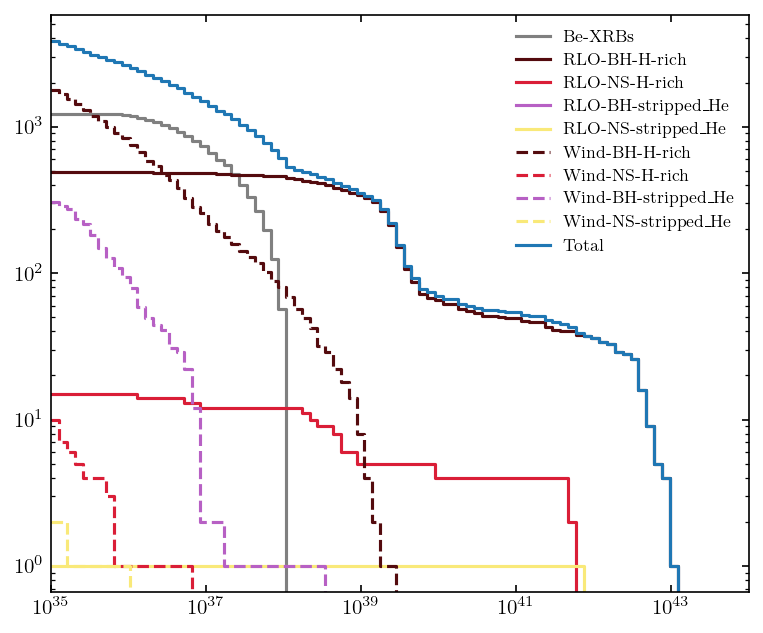

In [16]:
plt.figure(figsize=(6,5), dpi = 150)

h, bins = np.histogram(Final_Df['Lx'][Be_sys], bins=np.logspace(35, 45, 100))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', color = '#808080', label='Be-XRBs')

h, bins = np.histogram(Final_Df['Lx'][BH_RLO & H1_rich_RLO], bins=np.logspace(35, 45, 100))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'RLO-BH-H-rich', color ='#540B0E')

h, bins = np.histogram(Final_Df['Lx'][NS_RLO & H1_rich_RLO], bins=np.logspace(35, 45, 100))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'RLO-NS-H-rich', color ='#DA1E37')

h, bins = np.histogram(Final_Df['Lx'][BH_RLO & stripped_He_RLO], bins=np.logspace(35, 45, 100))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'RLO-BH-stripped_He', color='#B760C4')
h, bins = np.histogram(Final_Df['Lx'][stripped_He_RLO & NS_RLO], bins=np.logspace(35, 45, 100))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'RLO-NS-stripped_He', color='#F9E979')

h, bins = np.histogram(Final_Df['Lx'][BH_Wind & H1_rich_Wind], bins=np.logspace(35, 45, 100))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'Wind-BH-H-rich', linestyle='--', color='#540B0E')

h, bins = np.histogram(Final_Df['Lx'][NS_Wind & H1_rich_Wind], bins=np.logspace(35, 45, 100))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'Wind-NS-H-rich', linestyle='--', color='#DA1E37')

h, bins = np.histogram(Final_Df['Lx'][BH_Wind & stripped_He_Wind], bins=np.logspace(35, 45, 100))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'Wind-BH-stripped_He', linestyle='--', color='#B760C4')

h, bins = np.histogram(Final_Df['Lx'][NS_Wind & stripped_He_Wind], bins=np.logspace(35, 45, 100))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'Wind-NS-stripped_He', linestyle='--', color='#F9E979')

h, bins = np.histogram(Lx_Total, bins=np.logspace(35, 45, 100))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'Total', color = '#1F77B4')

plt.xscale('log')
plt.yscale('log')
plt.xlim(1e35, 1e44)
plt.legend()

## 2nd way of plotting

Without @np.vectorize

In [ ]:

def Eddington_limit(accretor_mass, Donor_surface_H1, eta):
    """
    Compute the Eddington accretion rate from the accretor mass, its accretion efficieny and the content of hydrogen at the surface of the donor star.
    Also compute the Eddington luminosity.

    Parameters
    ----------
    accretor_mass : float
        Mass of the accretor in [M⊙].
    Donor_surface_H1 : float
        Hydrogen mass fraction of the donor star's surface (surface_h1_f).
    eta : float
        Radiative efficiency of the accretor (NS or BH), dimensionless.

    Returns
    -------
    Mdot_Edd_gps : float
        Eddington accretion rate in [g/s].
    L_edd : float 
        Eddington luminosity in [erg/s].
    
    """
    L_edd = 4.0 * np.pi * const.standard_cgrav * accretor_mass * const.Msun * const.clight /(0.2 * (1.0 + Donor_surface_H1)) # [erg/s]

    Mdot_Edd_gps = L_edd / (eta * const.clight**2) # [g/s]

    return Mdot_Edd_gps, L_edd


def BH_efficiency(Spin): 
    """
    Compute the radiative efficiency of a Kerr black hole (or Schwarzschild BH if spin = 0)
    as a function of the spin parameter *a* and the mass according to Novikov-Thorne radiative efficiency [[1]_] .
    
    Parameters
    ---------- 
    Spin : float
        Spin of the black hole. Can be given as dimensionless spin "*a**" [c*J/(GM^2)] or dimensional spin "*a*" [J/M].
        Its value can be given either positively (prograde accretion) or negatively (retrograde accretion) 
        (Spin  ∈ [-0.998, 0.998] with ± 0.998 being the Thorne limit).

    Returns
    -------
    tuple
        A tuple with three floats: (eta, r_tilde).
        - eta (float): Radiative efficiency fof the Kerr black hole, dimensionless.
        - r_tilde (float): Radius of the ISCO in units of GM / c^2.

    References
    ----------
    .. [1] Bambi, C., Malafarina, D., & Tsukamoto, N. (2014).
            "Note on the radiation emitted by a thin accretion disk around a rotating compact object."
            *Phys. Rev. D*, 89(12), 127302. https://arxiv.org/abs/1406.2181
    """
    spin = np.asarray(Spin, dtype=float)

    # To control that the spin is in the range that gives the maximal efficiency
    a_star = np.clip(spin, -0.998, 0.998)

    #=== Compute efficiency [1]=== 
    
    # Use sign = +1 for spin ≥ 0 (prograde) and -1 otherwise (retrograde)
    sign = np.where(a_star >= 0.0, 1.0, -1.0)

    Z1 = 1 + (1 - a_star**2)**(1/3) * ((1 + a_star)**(1/3) + (1 - a_star)**(1/3))
    Z2 = np.sqrt(3 * a_star**2 + Z1**2)

    # Radius at the innermost stable circular orbit (ISCO)
    r_tilde = 3 + Z2 - sign * np.sqrt((3 - Z1)*(3 + Z1 + 2 * Z2)) # Dimensionless

    # Energy at ISCO in units of mc^2 (i.e E_ISCO < 1, E = 1 means particle energy at infinity)
    E_ISCO = (r_tilde**(3/2) - 2 * r_tilde**(1/2) + a_star)/(r_tilde**(3/4) * np.sqrt(r_tilde**(3/2) - 3 * r_tilde**(1/2) + 2 * a_star))
    
    # Radiative efficiency
    eta = 1 - E_ISCO

    return eta, r_tilde


def Stefan_Boltzmann_law(Luminosity, Radius):
    """
    Compute the effective temperature from the luminosity and radius of 
    a star using the Stefan-Boltzmann law.
    
    Parameters
    ----------
    Luminosity : float
        Luminosity of the star in [L⊙]
    Radius : float
        Radius of the star in [R⊙]

    Returns
    -------
    Teff : float
        Effective temperature of the star in [K].

    """

    #===== Check inputs =====
    if Luminosity <= 0.0 or Radius <= 0.0:
        Pwarn(f"Warning: Luminosity and Radius must be positive in L⊙ and R⊙ (PID={os.getpid()}). Returning NaN for Teff.",
              category="InappropriateValueWarning")
        return np.nan
    
    #===== Calculation =====
    Teff = ((Luminosity * const.Lsun) / (4.0 * np.pi * (Radius * const.Rsun)**2.0 * const.boltz_sigma))**(1.0/4.0)
    
    return Teff


def NS_efficiency(Mass,log_radius, B_surf=None, accretor_logMdot=None):
    """
    Compute the radiative efficiency of a neutron star as a function of its mass and radius. 
    
    If there is a magnetic field, it will compare the magnetospheric radius with the radius of the neutron star to compute the accretion radius accordingly to [[1]_]. 
    The strength of the magntic field affects the magnetospheric radius of the NS and therefore, if the magnetospheric radius is larger than the NS radius, 
    the efficiency is lowered because the accretion disk is truncated and accretion happens along the magnetic lines up to the poles on smaller surface area.
    This results as a beaming effect of the X-ray emission due to smaller accretion area.

    Parameters
    ----------
    mass : float
        Mass of the neutron star in [M⊙]
    log_radius : float
        Log10(Radius of the neutron star) in [R⊙]
    B_surf : float, optional
        Surface magnetic field strength of the neutron star in [G]. If provided along with accretor_logMdot, the magnetosphere radius will be computed.
    accretor_logMdot : float, optional
        Log10(Mass accretion rate onto the neutron star) in [M⊙/yr]. Required if B_surf is provided.
    
    Returns
    -------
    eta : float or ndarray
            Radiative efficiency of the neutron star, dimensionless.
    R : float or ndarray
            Accretion radius used for the efficiency computation in [cm]. It is either the NS radius or the magnetosphere radius if B_surf is provided and R_mag > R_NS.

    References
    ----------
    .. [1] Misra et al. (2024), Astronomy & Astrophysics, 682, A69,
           **Exploring the nature of Ultra-luminous X-ray sources across stellar population ages using detailed binary evolution calculations**
           https://doi.org/10.1051/0004-6361/202347880

    """
    
    #===== Mass =====
    mass_arr = np.asarray(Mass, dtype=float)
    
    mass = np.where(~np.isfinite(mass_arr) | (mass_arr <= 0.0), 1.45, mass_arr) 
        # Default 1.45 [M⊙] for Neutron stars if not given

    M = mass * const.Msun # [gr]

    #===== Radius =====
    logR_arr = np.asarray(log_radius, dtype=float)
    
    R_Ns_cm = np.where(np.isfinite(logR_arr), (10.0**(logR_arr)) * const.Rsun, 1.25e6) # Default radius [cm] for Neutron stars
        

    # If there is a magnetic field, compute the magnetosphere radius R_mag (POSYDON do not provide B field for now)
    R_mag = np.zeros_like(R_Ns_cm)
    if B_surf is not None and accretor_logMdot is not None:
        B_arr = np.asarray(B_surf, dtype=float)
        acc_log_mdot_arr = np.asarray(accretor_logMdot, dtype=float)
        mu = B_arr * R_Ns_cm**3  # Magnetic dipole moment [G cm^3]
        Mdot_NS = 10**acc_log_mdot_arr * const.Msun / const.secyer  # [g/s]
        R_mag = (mu**4 / (2 * const.standard_cgrav * M * Mdot_NS**2))**(1/7)  # [cm]
    
    # Choose the larger radius between R_NS and R_mag for the accretion radius.
    # If R_mag > R_Ns_cm, then magnetic field truncates the accretion disk, otherwise magnetosphere radius is within the NS radius
    R = np.where(R_mag > R_Ns_cm, R_mag, R_Ns_cm)


    #===== Efficiency computation =====
    eta = const.standard_cgrav * M /(R * const.clight**2) # dimensionless ~0.1-0.3
    
    return eta, R


def Wind_velocity_BHL(donor_mass, donor_logR, donor_logL, donor_log_mdot_wind, 
                      donor_surface_H1, donor_He_core_mass, 
                      Wind_velo_scheme ='Kudritzki+2000'):
    """
    Compute the wind velocity of the donor star in a detached binary system using either the prescription from :cite:`Hurley et al. 2002`   or :cite:`Kudritzki & Puls 2000`. 
    
    This wind velocity is relevant for the calculation of the BHL accretion rate in **BHL_mdot_acc()** for detached systems, 
    where the accretion happens through winds. 

    The states of the binary systems must already be filtered as 'detached'. The filtering happens in the function L_bolo(), where the wind velocity is only computed for systems in detached state. 

    Parameters
    ---------- 
    donor_mass : array of float
        Mass of the donor star in [M⊙].
    donor_logR : array of float
        Log10(Radius of the donor star) in [R⊙].
    donor_logL : array of float
        Log10(Luminosity of the donor star) in [L⊙].
    donor_log_mdot_wind : array of float
        Log10(Absolute mass loss rate of the donor star through winds) in [M⊙/yr].
    donor_surface_H1 : array of float
        Hydrogen mass fraction at the surface of the donor star.
    donor_He_core_mass : array of float
        Mass of the helium core of the donor star in [M⊙].
    Wind_velo_scheme : str, Default: 'Kudritzki+2000'
        Wind velocity calculation scheme to use. It can be either 'Hurley+2002' or 'Kudritzki+2000'.
        - 'Hurley+2002': It uses the prescription from Hurley et al. 2002, which depends on the mass, He core mass of the donor star, its radius as well as the abundance of hydrogen at surface. It distinguishes between H-rich and He-rich stars.
        - 'Kudritzki+2000' : It uses the prescription from Kudritzki & Puls 2000, which depends on the effective temperature of the donor star.

    Returns
    -------
    V_wind_out : array of float
        Wind velocity [cm/s]

    Raises
    ------
    ValueError
        If the wind velocity calculation scheme is not recognized.

    References
    ----------
    .. [1] Hurley, J. R., Tout, C. A., & Pols, O. R. 2002, MNRAS, 329, 897
    .. [2] Kudritzki, R.-P., & Puls, J. 2000, ARA&A, 38, 613
    .. [3] Sander A. A. C., Vink J. S., 2020, MNRAS, 499, 873

    """

    if Wind_velo_scheme not in ['Hurley+2002', 'Kudritzki+2000']:
        Pwarn(f"Wind_velo_scheme '{Wind_velo_scheme}' not recognized. Choose 'Hurley+2002' or 'Kudritzki+2000'. (PID={os.getpid()}).", category="InappropriateValueWarning")
        return np.full_like(donor_mass, np.nan, dtype=float)

    #===== Loading arrays =====
    donor_mass_arr = np.asarray(donor_mass, dtype=float)
    donor_logR_arr = np.asarray(donor_logR, dtype=float)
    donor_logL_arr = np.asarray(donor_logL, dtype=float)
    donor_log_mdot_wind_arr = np.asarray(donor_log_mdot_wind, dtype=float)
    donor_surface_H1_arr = np.asarray(donor_surface_H1, dtype=float)
    donor_He_core_mass_arr = np.asarray(donor_He_core_mass, dtype=float)

    arrays = [donor_mass_arr, donor_logR_arr, donor_logL_arr, donor_log_mdot_wind_arr,
              donor_surface_H1_arr, donor_He_core_mass_arr]
    shapes_non_scalar = {arr.shape for arr in arrays if arr.shape != ()}
    any_scalar = any(arr.shape == () for arr in arrays)

    # If shapes mismatch or scalars are mixed with arrays, warn and bail out
    if (any_scalar and shapes_non_scalar) or len(shapes_non_scalar) > 1:
        Pwarn(f"Wind_velocity_BHL: shape mismatch in inputs: {[arr.shape for arr in arrays]} (PID={os.getpid()}). Returning NaN.",
              category="InappropriateValueWarning")
        if shapes_non_scalar:
            shape = next(iter(shapes_non_scalar))
            return np.full(shape, np.nan, dtype=float)
        return np.nan

    #===== Calculations =====
    V_wind_out = np.zeros_like(donor_mass_arr)

    for idx in np.ndindex(donor_mass_arr.shape):
        donor_mass_i = donor_mass_arr[idx]
        donor_logR_i = donor_logR_arr[idx]
        donor_logL_i = donor_logL_arr[idx]
        donor_log_mdot_wind_i = donor_log_mdot_wind_arr[idx]
        donor_surface_H1_i = donor_surface_H1_arr[idx]
        donor_He_core_mass_i = donor_He_core_mass_arr[idx]

        Teff = Stefan_Boltzmann_law(10.0**donor_logL_i, 10.0**donor_logR_i) # [K]
        
        #===== Wind velocity calculation schemes =====
        # [1] Hurley et al. 2002
        if Wind_velo_scheme == 'Hurley+2002':
            # For H-rich stars
            if donor_surface_H1_i > 0.01:
                if donor_He_core_mass_i > 0.0 and 10.0**donor_logR_i > 900.0:
                    beta = 0.125
                elif donor_mass_i > 120.0:
                    beta = 7.0
                elif donor_mass_i < 1.4:
                    beta = 0.5
                else:
                    beta = 0.5 + (donor_mass_i - 1.4) / (120.0 - 1.4) * (6.5)
            else:  # For He-rich stars
                if donor_mass_i > 120.0:
                    beta = 7.0
                elif donor_mass_i < 10.0:
                    beta = 0.125
                else:
                    beta = 0.125 + (donor_mass_i - 10.0) / (120.0 - 10.0) * (6.875)
            f_m = float(np.sqrt(beta))

        # [2] Kudritzki & Puls 2000
        elif Wind_velo_scheme == 'Kudritzki+2000':
            if Teff >= 21000:
                f_m = 2.65
            elif Teff <= 10000:
                f_m = 1.0
            else:
                f_m = 1.4
        else:
            raise ValueError(f"Invalid scheme '{Wind_velo_scheme}'. Choose 'Hurley+2002' or 'Kudritzki+2000'.")

        V_esc = np.sqrt(2.0 * const.standard_cgrav * donor_mass_i * const.Msun / (10**donor_logR_i * const.Rsun)) # [cm/s]
        V_wind_val = f_m * V_esc  # [cm/s]

        # [3] Sander A. A. C., Vink J. S., 2020, MNRAS, 499, 873 
        if donor_surface_H1_i < 0.4 and Teff >= 1e4:
            if donor_log_mdot_wind_i >= -5.25:
                slope = (3.7 - 3.25) / (-2.5 + 5.25)
            else:
                slope = (3.25 - 3.75) / (-5.25 + 7.25)
            V_wind_val = 10 ** (slope * donor_log_mdot_wind_i + 3.25 + 5.25 * slope) * 1e5  # Convert from km/s to cm/s
        else:
            pass

        V_wind_out[idx] = V_wind_val

    return V_wind_out


def BHL_mdot_acc(Macc_Msun, donor_mass_Msun, accretor_type, donor_log_radius,
                 donor_log_mdot_wind, a_cm, ecc, V_wind, spin, **kwargs):
    """
    Compute the `Bondi-Hoyle-Lyttleton (BHL)`accretion rate for a detached binary system where the accretion happens through winds.
    These winds are assumed to be isotropic and the accretion is assumed to be spherically symmetric.

    Parameters
    ----------
    Macc_Msun : array of float
        Mass of the accretor in [M⊙].
    donor_mass_Msun : array of float
        Mass of the donor star in [M⊙].
    accretor_type : array of str
        Type of the accretor. It should be 'NS' or 'BH'.
    donor_log_radius : array of float
        Log10(Radius of the donor star) in [R⊙].
    donor_log_mdot_wind : array of float
        Log10(Absolute mass loss rate of the donor star through winds) in [M⊙/yr].
    a_cm : array of float
        Orbital separation in [cm].
    ecc : array of float
        Eccentricity of the orbit (dimensionless).
    V_wind : array of float
        Wind velocity of the donor star in [cm/s]. Comes from the function **Wind_velocity_BHL()**.
    spin : array of float
        Spin of the accretor. Only required for BH. It is the dimensionless spin parameter a* = cJ/(GM^2).
    **kwargs : dict, optional
        - alpha_BHL (float, *Default = 1.5*) : Dimensionless efficiency parameter for the BHL accretion rate and it should be in the range [1.0, 2.0]. 
            It accounts for the efficiency of the accretion process and can be used to calibrate the BHL accretion rate with observations or more detailed simulations.
        - Wind_Disk_BH_formation (bool, *Default = False*) : If True, it assumes that infalling material forms a disk around the BH before being accreted, which can increase the accretion efficiency.

    Returns
    -------
    Mdot_BHL_gps : array of float
        BHL accretion rate in [g/s].

    References
    ----------
    .. [1] Bondi, H., & Hoyle, F. 1944, MNRAS, 104, 273
    .. [2] Frank, J., King, A., & Raine, D. (2002). "Accretion Power in Astrophysics: Third Edition" Chapter 4.9 pages 73-74.
           *Cambridge University Press*. https://doi.org/10.1017/CBO9781139164417
    .. [3] Sen, K. ,Xu, X. -T., Langer, N., El Mellah, I. , Schurmann, C., Quast, M., 2021, A&A,
           Equation 10
    .. [4] Bambi, C., Malafarina, D., & Tsukamoto, N. (2014).
            "Note on the radiation emitted by a thin accretion disk around a rotating compact object."
            *Phys. Rev. D*, 89(12), 127302. https://arxiv.org/abs/1406.2181
    """

    #===== Optional parameters =====
    allowed_keys = {'alpha_BHL', 'Wind_Disk_BH_formation'}
    unknown = sorted(set(kwargs.keys()) - allowed_keys)
    
    alpha_BHL = kwargs.get('alpha_BHL', 1.5)
    if not (1.0 <= alpha_BHL <= 2.0):
        Pwarn("alpha_BHL must be in the range [1.0, 2.0]", category="InappropriateValueWarning")

    wind_disk = kwargs.get('Wind_Disk_BH_formation', False)
    if not isinstance(wind_disk, bool):
        Pwarn("Wind_Disk_BH_formation must be a boolean value (True or False)", category="InappropriateValueWarning")
        wind_disk = False

    if unknown:
        Pwarn(f"BHL_mdot_acc: unknown parameter(s): {unknown} (PID={os.getpid()})", category="InappropriateValueWarning")

    #===== Array conversion =====
    acc_mass_arr = np.asarray(Macc_Msun, dtype=float)
    don_mass_arr = np.asarray(donor_mass_Msun, dtype=float)
    acc_type_arr = np.asarray(accretor_type, dtype=object)
    logR_donor_arr = np.asarray(donor_log_radius, dtype=float)
    mdot_w_arr = np.asarray(donor_log_mdot_wind, dtype=float)
    a_arr = np.asarray(a_cm, dtype=float)
    ecc_arr = np.asarray(ecc, dtype=float)
    v_wind_arr = np.asarray(V_wind, dtype=float)
    spin_arr = np.asarray(spin, dtype=float)

    #===== Calculation Mdot BHL =====
    Mdot_BHL_gps = np.zeros_like(acc_mass_arr, dtype=float)

    for idx in np.ndindex(acc_mass_arr.shape):

        #=== Needed parameters ===
        Macc_i = float(acc_mass_arr[idx])
        Mdon_i = float(don_mass_arr[idx])
        acc_type_i = acc_type_arr[idx]
        Rdon_i = float(10**logR_donor_arr[idx] * const.Rsun)
        mdot_w_i = float(10**mdot_w_arr[idx])
        a_i = float(a_arr[idx])
        ecc_i = float(np.clip(ecc_arr[idx], 0.0, 0.999)) if np.isfinite(ecc_arr[idx]) else 0.0
        v_wind_i = float(v_wind_arr[idx])
        spin_i = float(spin_arr[idx])

        if not np.isfinite(a_i) or a_i <= 0.0 or not np.isfinite(v_wind_i) or v_wind_i < 0.0:
            Mdot_BHL_gps[idx] = 0.0
            continue

        # Masses to cgs
        Macc_cgs = Macc_i * const.Msun
        Mdon_cgs = Mdon_i * const.Msun

        #=== Orbital motion parameters ===

        # Orbital frequency [rad/s]
        Omega = np.sqrt(const.standard_cgrav * (Mdon_cgs + Macc_cgs) / Rdon_i**3)
        # Random orbital phase [s]
        t0 = np.random.rand() * (2.0 * np.pi / Omega)
        # Eccentric anomaly E at time t0 from Kepler's equation
        E = newton(lambda x: x - ecc_i * np.sin(x) - Omega * t0, np.pi/2, maxiter=100)
        b = a_i * np.sqrt(1.0 - ecc_i**2)
        r_vec = np.array([a_i * (np.cos(E) - ecc_i), b * np.sin(E)]) # Vectorial form radius
        v_dir = np.array([-a_i * np.sin(E), b * np.cos(E)]) # Vectorial form velocity (derivative of r_vec)
        R = np.linalg.norm(r_vec, axis=0) # Separation between stars [cm]
        v_dir_norm = np.linalg.norm(v_dir, axis=0)
        if R > 0.0 and v_dir_norm > 0.0:
            cos_angle = np.dot(v_dir, r_vec) / (v_dir_norm * R)
            cos_angle = np.clip(cos_angle, -1.0, 1.0)
        else:
            cos_angle = 0.0

        V_orb = np.sqrt(const.standard_cgrav * (Mdon_cgs + Macc_cgs) * (2.0 / R - 1.0 / a_i)) # Orbital velocity [cm/s]

        # Total relative velocity [cm] of winds [2]
        V_rel = np.sqrt(V_orb**2 + v_wind_i**2 + 2.0 * V_orb * v_wind_i * cos_angle) 

        #=== Mdot BHL calculation ===

        Mdot_w_cgs = mdot_w_i * const.Msun / const.secyer

        # From [1], calculation of BHL accretion rate
        if v_wind_i == 0.0:
            frac = 1.0
            Pwarn(
                f"Warning: Wind velocity is zero, setting accretion fraction to 1.0 (PID={os.getpid()})",
                category="InappropriateValueWarning",
            )
        elif V_rel == 0.0:
            frac = 0.0
            Pwarn(
                f"Warning: Orbital velocity is zero, setting BHL accretion rate to 0.0 g/s (PID={os.getpid()})",
                category="InappropriateValueWarning",
            )
        elif R == 0.0:
            frac = 0.0
            Pwarn(
                f"Warning: Orbital separation is zero, setting BHL accretion rate to 0.0 g/s (PID={os.getpid()})",
                category="InappropriateValueWarning",
            )
        else:
            frac = alpha_BHL * (const.standard_cgrav * Macc_cgs)**2 / (2 * V_rel**3 * v_wind_i * R**2)
        
        Mdot_BHL = frac * Mdot_w_cgs

        # From [3], check if an accretion disk can form around the BH accretor
        if wind_disk and acc_type_i == 'BH':
            eta_bh, r_ISCO_bh = BH_efficiency(spin_i)
            gamma = r_ISCO_bh / (6.0 * const.standard_cgrav * Macc_cgs / const.clight**2) # From [4]
            q = Mdon_cgs / Macc_cgs
            Rdisk_div_RISCO = (
                (2/3) * (eta_bh / (1 + q))**2 * (V_orb / (const.clight * 0.01))**(-2)
                * (1 + (v_wind_i / V_orb)**2)**(-4) / gamma
            )
            if Rdisk_div_RISCO < 1.0:
                Mdot_BHL = 1e-99  # avoid division by 0
                
        Mdot_BHL_gps[idx] = float(Mdot_BHL)

    return Mdot_BHL_gps if Mdot_BHL_gps.shape else float(Mdot_BHL_gps)


def Be_XRB_Lx(period, filtered = True):
    """
    Compute the X-ray luminosity of a system containing a Be star as companion. The donor star should have [[1]_]:
    - Surface velocity higher than 70% of its critical velocity
    - Orbital period between 10 and 300 days
    - The system state should be `detached` and not undergoing RLO
    - Donor mass of at least 6 M⊙
    - A decretion disc 100 times bigger than the star itself and it must go beyond the Roche-Lobe radius of the donor star

    The input parameter **filtered** is to check whether the population has already been filtered to contain only Be systems according to the description. 
    If the population is not already filtered, returns Lx = 0.0. 
    The `XRB_selection_function()`can be used to filter the population to contain only Be systems based on the criteria described above.

    Be stars have fast rotation surface which, when the surface velocity is close to the critical velocity,
    can form a decretion disk around them. The compact object (NS or BH) can then accrete material from this disk
    if it passes through the Roche lobe of the Be star and thus leading to X-ray emission when accreted.

    Parameters
    ----------
    orbital_period_days : float
        Orbital period of the binary system in [days].
    filtered :  bool (**Default** = True)
        If the population has already been filtered to contain only Be systems according to the description. 
        If the population is not already filtered, returns Lx = 0.0. 

    Returns
    -------
    Lx : float
        X-ray luminosity of the system [erg/s].
    
    References
    ----------
    .. [1] Misra, D., Kovlakas, K., Fragos, T., Lazzarini, M., Bavera, S. S.,  
           Lehmer, B. D., Zezas, A., Zapartas, E., Xing, Z., Andrews, J. J., Dotter, A.,  
           Rocha, K. A., Srivastava, P. M., Sun, M. (2023).  
           *X-ray luminosity function of high-mass X-ray binaries: Studying the signatures of different physical processes using detailed binary evolution calculations*. 
           https://arxiv.org/abs/2209.05505v2 
    .. [2] Dai, Hai-Lang ;  Liu, Xi-Wei ;  Li, Xiang-Dong (2006), Equation (11). 
           *Exploration of the Ps-Porb Relation for Wind-fed X-Ray Pulsars*.
           https://doi.org/10.1086/508735
    """

    if not filtered: 
        Pwarn(f"Be_XRB_Lx: Population not filtered for Be systems. Returning Lx = 0.0 for all systems (PID={os.getpid()}).", category="InappropriateValueWarning", stacklevel=2)
        Lx = np.zeros_like(period, dtype=float)
        return Lx
    # [2] Equation 11
    Lx = (10.0**35) * 10.0**(4.53 - (1.50 * np.log10(period)))

    return Lx


def L_bolo(bin_state, lg_mtransfer_rate, acc_log_mdot, donor_log_wind_mdot, acc_state, donor_log_L, 
           Macc, Mdonor, Acc_log_radius, Donor_log_radius, Donor_surface_H1, donor_He_core_mass, 
           Donor_RL_radius, a_cm, ecc, spin, B_surface, **kwargs):
    """ 
    This function calculates the bolometric luminosity (L_bolo) of a binary system based on its final 
    state and various physical parameters of the accretor and donor stars. 
    
    It calculates the geometrical beaming factor of a super-Eddington accreting system following 
    the prescription of King (2008) and applies it to the luminosity in the super-Eddington regime. 
    This is an observational effect due to the inflated structure of the accretion disk that beams 
    the outgoing X-ray emission. The function also checks for the presence of high wind rates based 
    on the donor star filling at least 80% of its Roche lobe following the prescription of 
    *Hirai & Mandel (2021)* to compute the luminosity in wind-fed systems.

    Requires that the input arrays have been through the XRB_selection_function to ensure that the 
    systems are X-ray binaries containing a NS or BH accretor and a non-degenerate donor star, and 
    that the binary state is either 'RLO1', 'RLO2' or 'detached' (wind-fed).

    Parameters
    ----------
    bin_state : array of str
        The final state of the binary system (e.g. 'RLO1', 'RLO2', 'detached', etc.).
    lg_mtransfer_rate : array of float
        Log10 of the mass transfer rate through Roche Lobe Overflow (RLO) in [M⊙/yr].
    acc_log_mdot : array of float
        Log10 of the mass changing rate of the accretor in [M⊙/yr].
    donor_log_wind_mdot : array of float
        Log10 of the absolute wind mass loss rate of the donor star in [M⊙/yr].
    acc_state : array of str
        The type of the accretor (e.g. 'NS' or 'BH').
    donor_log_L : array of float
        Log10 of the luminosity of the donor star in [L⊙].
    Macc : array of float
        Mass of the accretor in [M⊙].
    Mdonor : array of float
        Mass of the donor star in [M⊙].
    Acc_log_radius : array of float
        Log10 of the radius of the accretor in [R⊙].
    Donor_log_radius : array of float
        Log10 of the radius of the donor star in [R⊙].
    Donor_surface_H1 : array of float
        Hydrogen mass fraction at the surface of the donor star (surface_h1_f).
    donor_He_core_mass : array of float
        Mass of the helium core of the donor star in [M⊙].
    Donor_RL_radius : array of float
        Roche lobe radius of the donor star in [R⊙].
    a_cm : array of float
        Orbital separation in [cm].
    ecc : array of float
        Orbital eccentricity (dimensionless).
    spin : array of float
        Spin of the accretor (dimensionless).
    **kwargs : dict, optional
        - high_wind_rate : str, default=None
            Check whether the donor star fills at least 80% of its Roche lobe to get winds. Option : 'HiraiMandel21' chooses >= 80% filled systems.
    
    Returns
    -------
    Tuple of arrays
        Lx, Edd_state, beaming
        - Lx: X-ray luminosity of the system in [erg/s].
        - Edd_state: 'Sub-Eddington' or 'Super-Eddington' depending on whether the accretion rate is below or above the Eddington limit.
        - beaming: Beaming factor (b) applied to the luminosity in the super-Eddington regime, dimensionless.

    References
    ----------
    .. [1] Hirai, R. & Mandel, I. (2021).  
           *Conditions for accretion disc formation and observability of wind-accreting X-ray binaries.*. 
           Publications of the Astronomical Society of Australia, 38, e056.  
           https://doi.org/10.1017/pasa.2021.53
    .. [2] Misra, D., Kovlakas, K., Fragos, T., Lazzarini, M., Bavera, S. S.,  
           Lehmer, B. D., Zezas, A., Zapartas, E., Xing, Z., Andrews, J. J., Dotter, A.,  
           Rocha, K. A., Srivastava, P. M., Sun, M. (2023).  
           *X-ray luminosity function of high-mass X-ray binaries: Studying the signatures of different physical processes using detailed binary evolution calculations*.  
           https://arxiv.org/abs/2209.05505v2
    .. [3] Shakura, N. I. & Sunyaev, R. A. (1973).  
           *Black holes in binary systems. Observational appearance.*. 
           Astronomy and Astrophysics, 24, 337.  
           https://ui.adsabs.harvard.edu/abs/1973A%26A....24..337S
    .. [4] King, A. R. (2008).  
           *Accretion in compact binaries: the Eddington limit and beaming.*. 
           Monthly Notices of the Royal Astronomical Society, 385, L113.  
           https://ui.adsabs.harvard.edu/abs/2008MNRAS.385L.113K
    """

    #===== Optional parameters =====
    allowed_keys = {'high_wind_rate', 'alpha_BHL', 'Wind_Disk_BH_formation', 'Wind_velo_scheme'}
    unknown = sorted(set(kwargs.keys()) - allowed_keys)
    if unknown:
            Pwarn(f"L_bolo(): unknown parameter(s): {unknown} (PID={os.getpid()})", category="InappropriateValueWarning")

    high_wind_rate = kwargs.get('high_wind_rate', None)
    if high_wind_rate not in [None, 'HiraiMandel21']:
        Pwarn(f"high_wind_rate '{high_wind_rate}' not recognized. Choose 'HiraiMandel21' or None. (PID={os.getpid()}).", category="InappropriateValueWarning")

    # Passed to BHL_mdot_acc function
    BHL_kwargs = {key: kwargs[key] for key in ['alpha_BHL', 'Wind_Disk_BH_formation'] if key in kwargs}

    # Passed to Wind_velocity_BHL function
    Wind_velo_scheme = kwargs.get('Wind_velo_scheme', 'Kudritzki+2000')

    #===== Array conversion =====
    bin_state = np.asarray(bin_state, dtype=object)
    acc_state = np.asarray(acc_state, dtype=object)
    donor_log_L = np.asarray(donor_log_L, dtype=float)
    Macc = np.asarray(Macc, dtype=float)
    Mdonor = np.asarray(Mdonor, dtype=float)
    Acc_log_radius = np.asarray(Acc_log_radius, dtype=float)
    Donor_log_radius = np.asarray(Donor_log_radius, dtype=float)
    Donor_surface_H1 = np.asarray(Donor_surface_H1, dtype=float)
    donor_He_core_mass = np.asarray(donor_He_core_mass, dtype=float)
    Donor_RL_radius = np.asarray(Donor_RL_radius, dtype=float)
    a_cm = np.asarray(a_cm, dtype=float)
    ecc = np.asarray(ecc, dtype=float)
    spin = np.asarray(spin, dtype=float)
    lg_mtransfer_rate = np.asarray(lg_mtransfer_rate, dtype=float)
    acc_log_mdot = np.asarray(acc_log_mdot, dtype=float)
    donor_lgmdot_wind = np.asarray(donor_log_wind_mdot, dtype=float)
    B_surf = np.asarray(B_surface, dtype=float)

    #===== Masks =====
    mask_RLO = (bin_state == 'RLO1') | (bin_state == 'RLO2')
    mask_detached = (bin_state == 'detached')

    #===== Mass transfer rate through RLO =====
    Mdot_RLO_Msunyr = np.where(np.isfinite(lg_mtransfer_rate), 10.0**lg_mtransfer_rate, 0.0) # [M⊙/yr]
    Mdot_RLO_gps = Mdot_RLO_Msunyr * const.Msun / const.secyer  # [g/s]

    #===== Mdot calculation =====
    Mdot = np.full_like(Mdot_RLO_gps, np.nan, dtype=float)

    # RLO
    Mdot = np.where(mask_RLO, Mdot_RLO_gps, Mdot)

    # Winds
    Vwind = Wind_velocity_BHL(Mdonor, Donor_log_radius, donor_log_L, donor_lgmdot_wind, 
                              Donor_surface_H1, donor_He_core_mass, Wind_velo_scheme=Wind_velo_scheme)
    
    Mdot_BHL = BHL_mdot_acc(Macc, Mdonor, acc_state, Donor_log_radius, donor_lgmdot_wind, a_cm, ecc, Vwind, spin, **BHL_kwargs)
    
    Mdot = np.where(mask_detached, Mdot_BHL, Mdot)


    #===== Eddington parameters =====
    is_BH = (acc_state == 'BH')
    eta_ns, _ = NS_efficiency(Macc, Acc_log_radius, B_surf=B_surf, accretor_logMdot=acc_log_mdot)
    eta_bh, _ = BH_efficiency(spin)
    eta = np.where(is_BH, eta_bh, eta_ns)
    
    Medd, L_edd = Eddington_limit(Macc, Donor_surface_H1, eta)

    ratio = np.zeros_like(Mdot, dtype=float)
    mask_valid = np.isfinite(Medd) & (Medd > 0.0)
    ratio[mask_valid] = Mdot[mask_valid] / Medd[mask_valid]
    
    #===== Luminosity calculation =====

    Lx_sub = Mdot * eta * const.clight**2 # Sub-Eddington case

    if np.any(ratio == 0.0):
        Lx = np.where((Mdot == 0.0) & (ratio == 0.0), 1e-54, Lx_sub) # To avoid division by zero

    # Beaming
    b = np.ones_like(Mdot, dtype=float)
    mask_beam = ratio > 8.5
    if np.any(mask_beam):
        b_vals = np.maximum(73.0 / (ratio[mask_beam]**2), 3.2e-3)
        b[mask_beam] = b_vals

    Lx_super = (L_edd / b) * (1.0 + np.log(np.maximum(ratio, 1.0)))

    Edd_state = np.where(ratio <= 1.0, 'Sub-Eddington', 'Super-Eddington')
    beaming = b
    Lx = np.where(ratio <= 1.0, Lx_sub, Lx_super)

    # [1] Hirai & Mandel 2021
    if (high_wind_rate == 'HiraiMandel21'):
        mask_hirai = (10**Donor_log_radius / Donor_RL_radius < 0.8) & (bin_state == 'detached') & (acc_state == 'BH')
        Lx = np.where(mask_hirai, 10**(-54), Lx)
    

    return Lx, Edd_state, beaming


def XRB_selection_function(history_chunk, oneline_chunk, formation_channels_chunk, **kwargs):
    """ 
    A X-ray binary selection function to create a population of XRBs, where we store some important information (Only valid for **Population class** object).

    This function identifies X-ray binaries as an accretor and a donor star and returns their properties.
    Requires to have been through the System_selection() function to only have BH-star or NS-star systems to gain time.
    The function will also compute the X-ray luminosity of each selected binary system using the **L_bolo()** function and **Be_XRB_Lx()** function for Be systems.

    This function has to be passed to **Population_name.create_transient_population(XRB_selection_function,'Transient_population_name')** method to create a population of XRBs from a binary population synthesis simulation.

    
    Parameters
    ----------
    history_chunk : pd.DataFrame, optional
        A chunk of the history DataFrame from population class binaries. 
        Specific lines need to be provided. 
    oneline_chunk : pd.DataFrame
        A chunk of the oneline DataFrame from population class binaries.
    formation_channels_chunk : pd.DataFrame, optional
        A chunk of the formation channels DataFrame of the binaries. Default is None.
    **kwargs : dict, optional
        Additional arguments passed :
        - alpha_BHL (float, default = 1.5) : efficiency parameter for Bondi-Hoyle-Lyttleton accretion.
        - Wind_velo_scheme (str, default = 'Hurley+2002') : Wind velocity scheme to use in Wind_velocity_BHL function. 
        Can be either 'Hurley+2002' _[[4]] or 'Kudritzki+2000' _[[5]].
        - high_wind_rate (str, default = None) : Define a minimum threshold for filling the Roche lobe in order to obtain accretion winds. Option : 'HiraiMandel21' check ≥ 80% filled systems _[[3].
        - Wind_Disk_BH_formation (bool, default = False) : Whether to check for disk formation criteria around BH accretor _[[2]].

    Returns
    -------
    DF_XRBs : pd.DataFrame
        A DataFrame containing the selected XRBs with accretor/donor data and X-ray luminosities associated to each binary.
    
    References
    ----------
    .. [1] Misra, D., Kovlakas, K., Fragos, T., Lazzarini, M., Bavera, S. S.,  
           Lehmer, B. D., Zezas, A., Zapartas, E., Xing, Z., Andrews, J. J., Dotter, A.,  
           Rocha, K. A., Srivastava, P. M., Sun, M. (2023).  
           *X-ray luminosity function of high-mass X-ray binaries: Studying the signatures of different physical processes using detailed binary evolution calculations*.  
           https://arxiv.org/abs/2209.05505v2
    .. [2] Sen, K. ,Xu, X. -T., Langer, N., El Mellah, I. , Schurmann, C., Quast, M., A&A 652, A138 (2021)
           https://doi.org/10.1051/0004-6361/202141214
           Section 2.3.2, Equation 10
    .. [3] Hirai, R. & Mandel, I. (2021).  
           *Conditions for accretion disc formation and observability of wind-accreting X-ray binaries.*  
           Publications of the Astronomical Society of Australia, 38, e056.  
           doi:10.1017/pasa.2021.53  
           https://doi.org/10.1017/pasa.2021.53
    .. [4] Hurley, J. R., Tout, C. A., & Pols, O. R. 2002, MNRAS, 329, 897
    .. [5] Kudritzki, R.-P., & Puls, J. 2000, ARA&A, 38, 613

    Notes
    -----
    - The function is designed to be used with the Population class in posydon, and it assumes to contains the necessary 
    columns in the oneline DataFrame to identify XRBs and compute their properties. The required columns include, but are 
    not limited to : 
    - state_f, S1_state_f. S2_state_f, 
    - S1_mass_f, S2_mass_f, S1_log_R_f, S2_log_R_f, S1_log_L_f, S2_log_L_f, 
    - S1_surface_h1_f, S2_surface_h1_f, S1_He_core_mass_f, S2_He_core_mass_f,
    - S1_surf_avg_omega_div_omega_crit_f, S2_surf_avg_omega_div_omega_crit_f,
    - S1_spin_f, S2_spin_f, S1_lg_mdot_f, S2_lg_mdot_f, S1_log_wind_mdot_f, S2_log_wind_mdot_f,
    - lg_mtransfer_rate_f, orbital_period_f, time_f, metallicity


    Examples
    --------
    >>> from posydon.popsyn.synthetic_population import Population
    
    >>> pop = Population('Simulation_file.h5')
    >>> Systems_selection_XRB(pop, 'FileName')

    >>> selec_pop = Population('FileName.h5')
    >>> Transient_pop = selec_pop.create_transient_population(XRB_selection_function, 'Transient_Name')
    # Or, if you need to use kwargs in the selection function : 
    >>> Transient_pop = selec_pop.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, **kwargs), 'Transient_Name')

    """
    #===== Control and copy of the dataframes =====
    if not isinstance(oneline_chunk, pd.DataFrame):
        oneline_chunk = oneline_chunk[:]
    else:
        oneline_chunk = oneline_chunk.copy()

    if history_chunk is not None:
        if not isinstance(history_chunk, pd.DataFrame):
            history_chunk = history_chunk[:]
        else:        
            history_chunk = history_chunk.copy()

    if formation_channels_chunk is not None:
        if not isinstance(formation_channels_chunk, pd.DataFrame):
            formation_channels_chunk = formation_channels_chunk[:]
        else:
            formation_channels_chunk = formation_channels_chunk.copy()

    #===== Kwargs control =====
    allowed_keys = {'alpha_BHL', 'Wind_velo_scheme', 'high_wind_rate', 'Wind_Disk_BH_formation'}
    unknown = sorted(set(kwargs.keys()) - allowed_keys)
    if unknown:
        Pwarn(f"XRB_selection_function: unknown parameter(s): {unknown} (PID={os.getpid()})."
              f"These will be passed to downstream functions.", 
              category="InappropriateValueWarning")

    #===== Filtering Be-systems =====
    orbital_separation = orbital_separation_from_period(oneline_chunk['orbital_period_f'], oneline_chunk['S1_mass_f'], oneline_chunk['S2_mass_f'])

    Donor_RL_radius = roche_lobe_radius(oneline_chunk['S2_mass_f'].to_numpy(), oneline_chunk['S1_mass_f'].to_numpy(), orbital_separation)
    Donor_RL_series = pd.Series(Donor_RL_radius, index=oneline_chunk.index)

    mask_be = ((oneline_chunk['S2_state_f'] == 'H-rich_Core_H_burning')
                & (oneline_chunk['S2_mass_f'] >= 6.0)
                & (oneline_chunk['state_f'] == 'detached')
                &  (oneline_chunk['S2_surf_avg_omega_div_omega_crit_f'] >= 0.7)
                & (oneline_chunk['orbital_period_f'] >= 10.0)
                & (oneline_chunk['orbital_period_f'] <= 300.0)
                & (Donor_RL_radius <= (100.0 * 10**(oneline_chunk['S2_log_R_f'])))
                )

    Df_Be = oneline_chunk[mask_be].copy()
    Df_Be['Binary_state'] = 'Be system'
    Df_Be['System_type'] = 'Be'
    Df_Be['metallicity'] = oneline_chunk.loc[mask_be, 'metallicity']
    Df_Be['time_f'] = oneline_chunk.loc[mask_be, 'time_f']
    Df_Be['Lx'] = Be_XRB_Lx(oneline_chunk.loc[mask_be, 'orbital_period_f'].to_numpy())

    if formation_channels_chunk is not None:
        Df_Be['formation_channel'] = formation_channels_chunk.loc[Df_Be.index, 'channel']

    Df_Be['Donor_Roche_Lobe_radius'] = Donor_RL_series.loc[Df_Be.index].to_numpy()
    
    #===== RLO / Winds systems =====
    Rest_of_systems = oneline_chunk.loc[~mask_be].copy()
    RLO_mask = Rest_of_systems['state_f'].isin(['RLO1', 'RLO2'])
    RLO_systems = Rest_of_systems.loc[RLO_mask].copy()
    Wind_mask = Rest_of_systems['state_f'] == 'detached'
    Wind_systems = Rest_of_systems.loc[Wind_mask].copy()

    Rest_Donor_RL_radius = Donor_RL_series.loc[~mask_be]


    rows = []

    for name, df in {'RLO' : RLO_systems, 'Wind' : Wind_systems}.items():

        final_state = df['S1_state_f']
        is_S1_compact = final_state.isin(['NS', 'BH'])

        Macc = np.where(is_S1_compact, df['S1_mass_f'], df['S2_mass_f'])
        Mdonor = np.where(is_S1_compact, df['S2_mass_f'], df['S1_mass_f'])
        Acc_log_radius = np.where(is_S1_compact, df['S1_log_R_f'], df['S2_log_R_f'])
        Donor_log_radius = np.where(is_S1_compact, df['S2_log_R_f'], df['S1_log_R_f'])
        acc_state = np.where(is_S1_compact, df['S1_state_f'], df['S2_state_f'])
        donor_state = np.where(is_S1_compact, df['S2_state_f'], df['S1_state_f'])
        acc_log_mdot = np.where(is_S1_compact, df['S1_lg_mdot_f'], df['S2_lg_mdot_f'])
        donor_log_wind_mdot = np.where(is_S1_compact, df['S2_lg_wind_mdot_f'], df['S1_lg_wind_mdot_f'])
        Donor_surface_H1 = np.where(is_S1_compact, df['S2_surface_h1_f'], df['S1_surface_h1_f'])
        donor_He_core_mass = np.where(is_S1_compact, df['S2_he_core_mass_f'], df['S1_he_core_mass_f'])
        spin_acc = np.where(is_S1_compact, df['S1_spin_f'], df['S2_spin_f'])
        Donor_log_lum = np.where(is_S1_compact, df['S2_log_L_f'], df['S1_log_L_f'])

        bin_state = df['state_f']
        lg_mtransfer_rate = df['lg_mtransfer_rate_f']
        a_cm = const.Rsun * orbital_separation_from_period(df['orbital_period_f'], df['S1_mass_f'], df['S2_mass_f'])
        Donor_RL_radius = Rest_Donor_RL_radius.loc[df.index].to_numpy()
        ecc = df['eccentricity_f']

        # If the magnteic field of the NS is available, we can compute the magnetosphere radius and thus the accretion efficiency more accurately. 
        # If not, we assume that the accretion radius is the NS radius. For the moment, magnetic field is not available in simulations, so we set it to None.
        # But if it becomes available, it can be added to the input dataframe and this part of the code can be updated.
        B_surface = None 

        Lx, Edd_state, beaming = L_bolo(
            bin_state, lg_mtransfer_rate, acc_log_mdot, donor_log_wind_mdot, acc_state,
            Donor_log_lum, Macc, Mdonor, Acc_log_radius, Donor_log_radius,
            Donor_surface_H1, donor_He_core_mass, Donor_RL_radius, a_cm, ecc, spin_acc, B_surface,
            **kwargs
        )


        out = pd.DataFrame(index=df.index)
        out['metallicity'] = df['metallicity']
        out['time'] = df['time_f']
        out['Binary_state'] = bin_state
        out['Accretor_state'] = acc_state
        out['Accretor_spin'] = spin_acc
        out['Accretor_mass'] = Macc
        out['Accretor_LogR'] = Acc_log_radius
        out['Donor_state'] = donor_state
        out['Donor_mass'] = Mdonor
        out['Donor_LogR'] = Donor_log_radius
        out['Donor_Roche_lobe_radius'] = Donor_RL_radius
        out['Donor_LogL'] = Donor_log_lum
        out['Donor_H1_at_surface'] = Donor_surface_H1
        out['Donor_He_Core_mass'] = donor_He_core_mass
        out['Accretor_LogMdot'] = acc_log_mdot
        out['Donor_LogMdot_wind'] = donor_log_wind_mdot
        out['lg_mtransfer_rate'] = lg_mtransfer_rate
        out['Orbital_separation'] = a_cm
        out['Eccentricity'] = ecc
        out['System_type'] = name
        out['Eddington_state'] = Edd_state
        out['Beaming'] = beaming
        out['Lx'] = Lx
        if formation_channels_chunk is not None:
            out['formation_channel'] = formation_channels_chunk.loc[df.index, 'channel']

        rows.append(out)

    final_df = pd.concat(rows + [Df_Be], axis=0, ignore_index=False)

    keep_cols = ['metallicity', 'time', 'lg_mtransfer_rate',
    'Binary_state','Accretor_state','Accretor_spin','Accretor_mass','Accretor_LogR',
    'Donor_state','Donor_mass','Donor_LogR','Donor_Roche_lobe_radius','Donor_LogL',
    'Donor_H1_at_surface','Donor_He_Core_mass','Accretor_LogMdot','Donor_LogMdot_wind',
    'Orbital_separation','Eccentricity','System_type','Beaming', 'Eddington_state','Lx', 'formation_channel']

    final_df = final_df[keep_cols].copy()

    return final_df

In [ ]:

def Compute_IMF_normalization_correction(Population, m_min = 0.01, m_max = 200.0):
    '''
    Compute the IMF-based normalization correction factor used to relate
    a simulated population of massive-star binaries to the total stellar
    mass formed in a star-forming event.

    This correction follows the method described in Appendix A of Bavera et al. (2020, A&A 635, A97, doi:10.1051/0004-6361/201936204).

    Parameters
    ----------
    Population : Population
        A Population object containing the initial parameters of the population synthesis simulation.
    m_min : float, optional
        Minimum stellar mass considered for the normalization [M⊙]. Default is 0.01.
    m_max : float, optional
        Maximum stellar mass considered for the normalization [M⊙]. Default is 200.0. 
        The upper mass limit is restricted to 300 M⊙, corresponding to the maximum ZAMS mass covered by the MESA grids used in POSYDON.

    Returns
    -------
    normalization : float
        The IMF-based normalization correction factor (dimensionless). 
        normalization = 1 / (fraction of total mass formed in stars that is represented by the modeled population).

    References
    ----------
    .. [1]  Bavera, S. S., Fragos, T., Zevin, M., et al. (2020).
            *The origin of spin in binary black holes.*
            Astronomy & Astrophysics, 635, A97.
            DOI: 10.1051/0004-6361/201936204.

    Notes
    -----
    This function assumes that the Population object has an attribute
    `ini_params` which is a dictionary containing the initial parameters
    of the population synthesis simulation, including the primary mass
    scheme and binary fraction scheme. 
    In the appendix A calculation, the factor f_0 is set such as the integral of the IMF (f(m)) over [m_min, m_max] is equal to 1.
    In the final formula, this factor f_0 cancels out, so it is not explicitly calculated here.
    The mass ratio _q_ distribution is assumed to be flat in [0, 1]. 

    '''

    Ini_params = Population.ini_params.copy()

    # Extract relevant parameters
    primary_mass_scheme = Ini_params.get('primary_mass_scheme', 'Kroupa2001')
    m_A = Ini_params.get('primary_mass_min', 5.0)
    m_B = Ini_params.get('primary_mass_max', 150.0)
    sec_mass_scheme = Ini_params.get('secondary_mass_scheme', 'flat_mass_ratio')
    binary_fraction_const = Ini_params.get('binary_fraction_const', 0.7)

    if sec_mass_scheme != 'flat_mass_ratio':
        raise NotImplementedError(f"The secondary_mass_scheme has to be 'flat_mass_ratio' for Compute_IMF_normalization_correction. Got '{sec_mass_scheme}' instead.")
    
    if primary_mass_scheme != 'Kroupa2001':
        raise NotImplementedError(f"Compute_IMF_normalization_correction: primary_mass_scheme '{primary_mass_scheme}' not implemented yet.")
    
    if not (0.01 <= m_min < m_A < m_B < m_max <= 300):
        raise ValueError(f"Compute_IMF_normalization_correction: m_min and m_max must be within [0.01, 300] and cover at least the range of simulated primary masses.\n Primary_mass_min : {m_A}\n Primary_mass_max : {m_B}")
    
    # Kroupa (2001) IMF parameters
    alpha1 = 0.3
    alpha2 = 1.3
    alpha3 = 2.3
    m_break1 = 0.08 # [M⊙] - Transition slope from alpha1 to alpha2
    m_break2 = 0.5  # [M⊙] - Transition slope from alpha2 to alpha3

    # Mean mass of stellar systems in the population : 
    mstar_mean = (1 + binary_fraction_const/2) * (1 / (2 - alpha1) * (m_break1**(2 - alpha1) - m_min**(2 - alpha1)) / m_min**(-alpha1) 
                                                  + 1 / (2 - alpha2) * (m_break1 / m_min)**(-alpha1) * (m_break2**(2 - alpha2) - m_break1**(2 - alpha2)) / m_break1**(-alpha2)
                                                  + 1 / (2 - alpha3) * (m_break1 / m_min)**(-alpha1) * (m_break2 / m_break1)**(-alpha2) * 
                                                    (m_max**(2 - alpha3) - m_break2**(2 - alpha3)) / m_break2**(-alpha3))
    
    # Fraction of systems that are modeled if m_A, m_B > m_break2
    f_model = (binary_fraction_const * 1 / (1 - alpha3) * (m_break1 / m_min)**(-alpha1) * (m_break2/m_break1)**(-alpha2) 
              * (m_B**(1 - alpha3) - m_A**(1 - alpha3)) / (m_break2**(-alpha3)))
    
    # Mean mass of a binary system in the modelled population :
    mstar_model_mean = 3/2 * (1- alpha3) / (2 -alpha3) * (m_B**(2 - alpha3) - m_A**(2 - alpha3)) / (m_B**(1 - alpha3) - m_A**(1 - alpha3))

    # The total modeled mass represnets only a fraction of the total mass formed in stars.
    correction_factor = f_model * mstar_model_mean / mstar_mean

    # Normilization with the inverse of the correction factor
    normalization = 1 / correction_factor

    return float(normalization)


def Stat_XLF(transient_population, Lmin=1e30, SFR = 1.0, stat_kwargs=None):
    '''
    Compute statistics for a given transient population of XRBs, including the weigthed cumulative number of XRBs above a given luminosity.

    Parameters
    ----------
    transient_population : TransientPopulation object
        A transient population of XRBs.
    Lmin : float, optional
        Minimum luminosity threshold for XRBs [erg/s]. Default is 1e30.
    SFR : float, optional
        Star formation rate [M⊙/yr]. Default is 1.0. (E.g. Milky-Way SFR ~ 1.5 M⊙/yr. Starburst galaxies SFR ~ 10 M⊙/yr)
    stat_kwargs : dict, optional
        A dictionary of population parameters to override the default ones used in the transient population in order to weight the population accordingly.
        See Notes for allowed keys. Default is *None*.

    Returns
    -------
    L_sorted : np.ndarray
        Sorted array of X-ray luminosities [erg/s].
    N_weighted : np.ndarray
        Weighted cumulative number of XRBs above each luminosity [number].
    weights : pd.Series
        Weights associated with each XRB in the population.

    References
    ----------
    .. [1] Misra, D., Kovlakas, K., Fragos, T., Lazzarini, M., Bavera, S. S.,  
           Lehmer, B. D., Zezas, A., Zapartas, E., Xing, Z., Andrews, J. J., Dotter, A.,  
           Rocha, K. A., Srivastava, P. M., Sun, M. (2023).  
           *X-ray luminosity function of high-mass X-ray binaries: Studying the signatures of different physical processes using detailed binary evolution calculations*.  
           https://arxiv.org/abs/2209.05505v2
    .. [2] Bavera, S. S., Fragos, T., Zevin, M., et al. (2020). 
           *The origin of spin in binary black holes.* 
           Astronomy & Astrophysics, 635, A97. 
           DOI: 10.1051/0004-6361/201936204.

    Notes
    -----
    The function uses the calculate_model_weights method of the TransientPopulation class to compute weights based on the specified population parameters.
    For that, you can provide a dictionary of population parameters to override the default ones used in the transient population in order to weight the population accordingly.
    Therefore, the allowed keys in the pop_params dictionary are:
    - 'number_of_binaries'
    - 'binary_fraction_scheme', 'binary_fraction_const'
    - 'star_formation'
    - 'max_simulation_time'
    - 'primary_mass_scheme', 'primary_mass_min', 'primary_mass_max'
    - 'secondary_mass_scheme', 'secondary_mass_min', 'secondary_mass_max'
    - 'orbital_scheme', 'orbital_period_scheme', 'orbital_period_min', 'orbital_period_max'
    - 'eccentricity_scheme'
    - 'q_min', 'q_max'
    
    Example
    -------
    >>> stat_kwargs = {'primary_mass_min': 0.01, 'primary_mass_max': 200.0, 'q_min': 0.0, 'q_max': 1.0,}
    >>> L_sorted, N_weighted, weights = Stat_XLF(transient_population, Lmin=1e30, Tot_underlying_mass=1e8, stat_kwargs=stat_kwargs)

    '''

    #===== Statistics Kwargs =====

    # Keys allowed in calculate_model_weights()
    from posydon.popsyn.binarypopulation import saved_ini_parameters

    _allowed_keys = set(saved_ini_parameters) | {"q_min", "q_max"}

    Pop_params = transient_population.ini_params.copy()

    if stat_kwargs is not None:
        if not isinstance(stat_kwargs, dict):
            raise TypeError("stat_kwargs must be a dict or None.")
        stat_keys = set(stat_kwargs)
        if not stat_keys.issubset(_allowed_keys):
            bad = sorted(stat_keys - _allowed_keys)
            raise ValueError(
                f"Stat_XLF: Invalid population parameter(s): {bad}. Allowed keys: {sorted(_allowed_keys)}"
            )
        for key, value in stat_kwargs.items():
            Pop_params[key] = value


    T_window_yr = Pop_params['max_simulation_time'] # Years
    Tot_underlying_mass = SFR * T_window_yr  # Total underlying mass in M⊙

    base_w = transient_population.calculate_model_weights(model_weights_identifier="base_IMF",
                                                          population_parameters=Pop_params)
    
    if isinstance(base_w, pd.DataFrame):
        # prefer the named column if present, else take first column
        if "base_IMF" in base_w.columns:
            weights_series = base_w["base_IMF"].to_numpy(float)
        else:
            weights_series = base_w.iloc[:, 0].to_numpy(float)
    else:
        weights_series = np.asarray(base_w, float)  # assume Series-like
    
    Weights = weights_series * Tot_underlying_mass

    return Weights


def plot_ccdf(transient_population, ax, weights, mask, label, SFR = 1.0, **ccdf_kwargs):
    '''
    Compute the cumulative X-ray luminosity function (CCDF) of a given transient populations. 
    This function returns a *time-averaged* CCDF, i.e. the expected number of X-ray binaries brighter than L at a random time, 
    assuming constant star formation over a time window T_window_Myr.\n
    Masks split the population into different sub-populations to be plotted separately (e.g. RLO, Wind-fed, Be-XRBs, etc.).

    Parameters
    ----------
    transient_population : TransientPopulation object
        The transient population.
    SFR : float, optional
        Star formation rate [M⊙/yr]. Default is 1.0. (E.g. Milky-Way SFR ~ 1.5 M⊙/yr. Starburst galaxies SFR ~ 10 M⊙/yr)
    ax : matplotlib.axes.Axes
        The axes on which to plot the CCDF (_fig , ax = plt.subplots(*args, **kwargs)_).
    weights : array-like
        The weights associated with each value.
    mask : array-like
        A boolean mask to filter the values.
    label : str
        The label for the CCDF plot.
    linestyle : str
        The line style for the CCDF plot.
    **kwargs : dict, optional
        Additional keyword arguments for customization.
        - norm_factor (float, default=0.5) : Normalization factor L_x/L_bolo ~ 0.5 from Misra et al.[1] page 4
        - extend_to_edges (bool, default=True) : Whether to extend the CCDF to the edges of the plot.
    
        Any other keyword arguments valid for `matplotlib.pyplot` can be passed.

    Returns
    -------
    None

    References
    ----------
    .. [1] Misra, D., Kovlakas, K., Fragos, T., Lazzarini, M., Bavera, S. S.,  
           Lehmer, B. D., Zezas, A., Zapartas, E., Xing, Z., Andrews, J. J., Dotter, A.,  
           Rocha, K. A., Srivastava, P. M., Sun, M. (2023).  
           *X-ray luminosity function of high-mass X-ray binaries: Studying the signatures of different physical processes using detailed binary evolution calculations*.  
           https://arxiv.org/abs/2209.05505v2
    Notes
    -----
    * Weights are assumed to already include IMF, binary fraction, and population 
    synthesis corrections

    Example
    -------
    >>> fig, ax = plt.subplots()
    >>> plot_ccdf(transient_population, ax, weights, mask, label='Label name', color='blue', linestyle='-')

    '''
    #===== kwargs =====
    controlled_keys = {'norm_factor', 'extend_to_edges'}

    plot_keys = dict(label=label)
    extra_plot_keys = {key: var for key, var in ccdf_kwargs.items() if key not in controlled_keys}
    plot_keys.update(extra_plot_keys)
 
    extend_to_edges = ccdf_kwargs.get('extend_to_edges', True) # Whether to extend the CCDF to the edges of the plot
    norm_factor = ccdf_kwargs.get('norm_factor', 0.5) # Normalization factor L_x/L_bolo ~ 0.5 from Misra et al.[1] page 4

    if norm_factor <= 0.0:
        raise ValueError("plot_ccdf: norm_factor must be > 0.0")

    L = np.log10(transient_population.population['Lx'].to_numpy(dtype = float) * norm_factor)

    T_window_yr = transient_population.ini_params.get('max_simulation_time', 1e8) # Years
    Total_underlying_mass = SFR * T_window_yr  # Total underlying mass in M⊙

    if Total_underlying_mass <= 0.0:
        raise ValueError("plot_ccdf: Total_underlying_mass must be > 0.0")

    b = transient_population.population['Beaming'].to_numpy(dtype = float)
    b = np.where(np.isfinite(b) & (b > 0.0), b, 1.0)

    selection = mask & np.isfinite(L) & (L >= 35)

    if not np.any(selection):
        return

    L_selec = L[selection]
    Weight_select = weights[selection] * b[selection]

    order = np.argsort(L_selec)
    L_sorted = L_selec[order]
    Weights_sorted = Weight_select[order]

    N = np.cumsum(Weights_sorted[::-1])[::-1]  # Cumulative sum from the end to the beginning


    if extend_to_edges:
        cur_xlim = ax.get_xlim()
        if cur_xlim == (0.0, 1.0):
            xmin, xmax = float(L_sorted[0]), float(L_sorted[-1])
        else:
            xmin, xmax = cur_xlim
        cur_ylim = ax.get_ylim()
        if cur_ylim == (0.0, 1.0):
            ymin = np.nextafter(0, 1)
        else:
            ymin = cur_ylim[0]

    # Valeur totale au-dessus du plus petit L
        y0 = float(np.sum(Weights_sorted))

        x_ext = np.r_[xmin, L_sorted, xmax]
        y_ext = np.r_[y0, N, ymin]

        ax.plot(x_ext, y_ext, **plot_keys)
    else:
        ax.plot(L_sorted, N, **plot_keys)


In [ ]:
def Plot_cumulative_XLF(transient_population, weights, SFR = 1.0, title=None, **plot_kwargs):
    '''
    Plot the cumulative X-ray luminosity function (CCDF) of a given transient population of XRBs.

    Parameters
    ----------
    transient_population : TransientPopulation object
        The transient population.
    weights : array-like
        The weights associated with each value.
    SFR : float, optional
        Star formation rate [M⊙/yr]. Default is 1.0. (E.g. Milky-Way SFR ~ 1.5 M⊙/yr. Starburst galaxies SFR ~ 10 M⊙/yr)
    **plot_kwargs : dict, optional
        Additional keyword arguments for customization of the plot.
        See Notes for allowed keys.

    Returns
    -------
    fig : matplotlib.figure.Figure
        The figure object containing the plot.
    ax : matplotlib.axes.Axes
        The axes object containing the plot.

    Notes
    -----
    Allowed keys in plot_kwargs:
    - norm_factor (float, default=0.5) : Normalization factor L_x/L_bolo ~ 0.5 from Misra et al.[1] page 4
    - extend_to_edges (bool, default=True) : Whether to extend the CCDF to the edges of the plot.
    
    Any other keyword arguments valid for `matplotlib.pyplot` can be passed and will be forwarded to the plot_ccdf function.
    '''

    met = transient_population.population['metallicity'][0] if 'metallicity' in transient_population.population.columns else None
    title = f"{title} (Z={met:.2e} $Z_{{\odot}}$)" if title and met is not None else title


    Lumino_range = (np.log10(transient_population.population['Lx'] * 0.5) >= 35) & (np.log10(transient_population.population['Lx'] * 0.5) <= 43) #1e35) #1e43)
    RLO = transient_population.population['System_type'] == 'RLO'
    Be_XRB = transient_population.population['Binary_state'] == 'Be system' 
    Wind = transient_population.population['System_type'] == 'Wind'

    BH = transient_population.population['Accretor_state'] == 'BH'
    NS = transient_population.population['Accretor_state'] == 'NS'

    H1_rich = transient_population.population['Donor_state'].str.contains('H-rich|accreted_He', regex=True, na=False)
    He_rich = transient_population.population['Donor_state'].str.contains('stripped_He', na=False)


    fig , ax = plt.subplots(figsize=(10,8), dpi=300)
    plot_ccdf(transient_population, ax, weights, Lumino_range, 'Total XRB population', SFR = SFR, linestyle='-', color='#1F77B4', **plot_kwargs)
    plot_ccdf(transient_population, ax, weights, Lumino_range & Be_XRB, 'Be-XRBs', SFR = SFR, linestyle=':', color='#808080',**plot_kwargs)
    plot_ccdf(transient_population, ax, weights, Lumino_range & RLO & BH & He_rich, 'RLO BH-He-rich', SFR = SFR, linestyle='-', color='#B760C4', **plot_kwargs)
    plot_ccdf(transient_population, ax, weights, Lumino_range & RLO & BH & H1_rich, 'RLO BH-H-rich', SFR = SFR, linestyle='-', color='#540B0E', **plot_kwargs)
    plot_ccdf(transient_population, ax, weights, Lumino_range & RLO & NS & He_rich, 'RLO NS-He-rich', SFR = SFR, linestyle='-', color='#F9E979', **plot_kwargs)
    plot_ccdf(transient_population, ax, weights, Lumino_range & RLO & NS & H1_rich, 'RLO NS-H-rich', SFR = SFR, linestyle='-', color='#DA1E37', **plot_kwargs)
    plot_ccdf(transient_population, ax, weights, Lumino_range & Wind & BH & He_rich, 'Wind BH-He-rich', SFR = SFR, linestyle='--', color='#B760C4', **plot_kwargs)
    plot_ccdf(transient_population, ax, weights, Lumino_range & Wind & BH & H1_rich, 'Wind BH-H-rich', SFR = SFR, linestyle='--', color='#540B0E', **plot_kwargs)
    plot_ccdf(transient_population, ax, weights, Lumino_range & Wind & NS & He_rich, 'Wind NS-He-rich', SFR = SFR, linestyle='--', color='#F9E979', **plot_kwargs)
    plot_ccdf(transient_population, ax, weights, Lumino_range & Wind & NS & H1_rich , 'Wind NS-H-rich', SFR = SFR, linestyle='--', color='#DA1E37', **plot_kwargs)


    ax.set_title(title if title else r'XLF of XRBs population', pad = 100, fontsize=18)
    ax.set_yscale('log')
    ax.set_xlabel(r'$\log_{10}\left(L_{\mathrm{X},\,0.5-8\,\mathrm{keV}} \,/\, \mathrm{erg\,s^{-1}}\right)$', fontsize=16)
    ax.set_ylabel(r'$N(> L_{\mathrm{X},\,0.5-8\,\mathrm{keV}})\,/\,(\mathrm{M}_\odot\,\mathrm{yr}^{-1})$', fontsize=16)
    ax.tick_params(axis='both', which='both', labelsize=16)
    ax.set_xlim(35, 43)
    ax.set_ylim(2e-4, 4e2)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), bbox_transform=ax.transAxes, 
              ncol=3, frameon=True, fancybox=True, edgecolor='k', handlelength=1.5, borderpad=0.4, fontsize=16)
    fig.subplots_adjust(top=0.8)  # ajuster l'espace supérieur pour la légende

    
    return fig, ax

### With create_transient_population()

#### Default population

In [8]:
Trans_pop = selection.create_transient_population(XRB_selection_function, 'XRB_population')
Trans_pop2 = selection2.create_transient_population(XRB_selection_function, 'XRB_population2')

overwriting transient population
overwriting transient population


In [6]:
stat_kwargs = {'primary_mass_min': 0.01,
               'primary_mass_max': 200.0,
               'secondary_mass_min': 0.01,
               'secondary_mass_max': 150.0,
               'orbital_period_min': 0.75,
               'orbital_period_max': 10**5.5,
               'q_min': 0.05,
               'q_max': 1.0,}

In [ ]:
Weights = Stat_XLF(Trans_pop, stat_kwargs=stat_kwargs)
Weights2 = Stat_XLF(Trans_pop2, stat_kwargs=stat_kwargs)

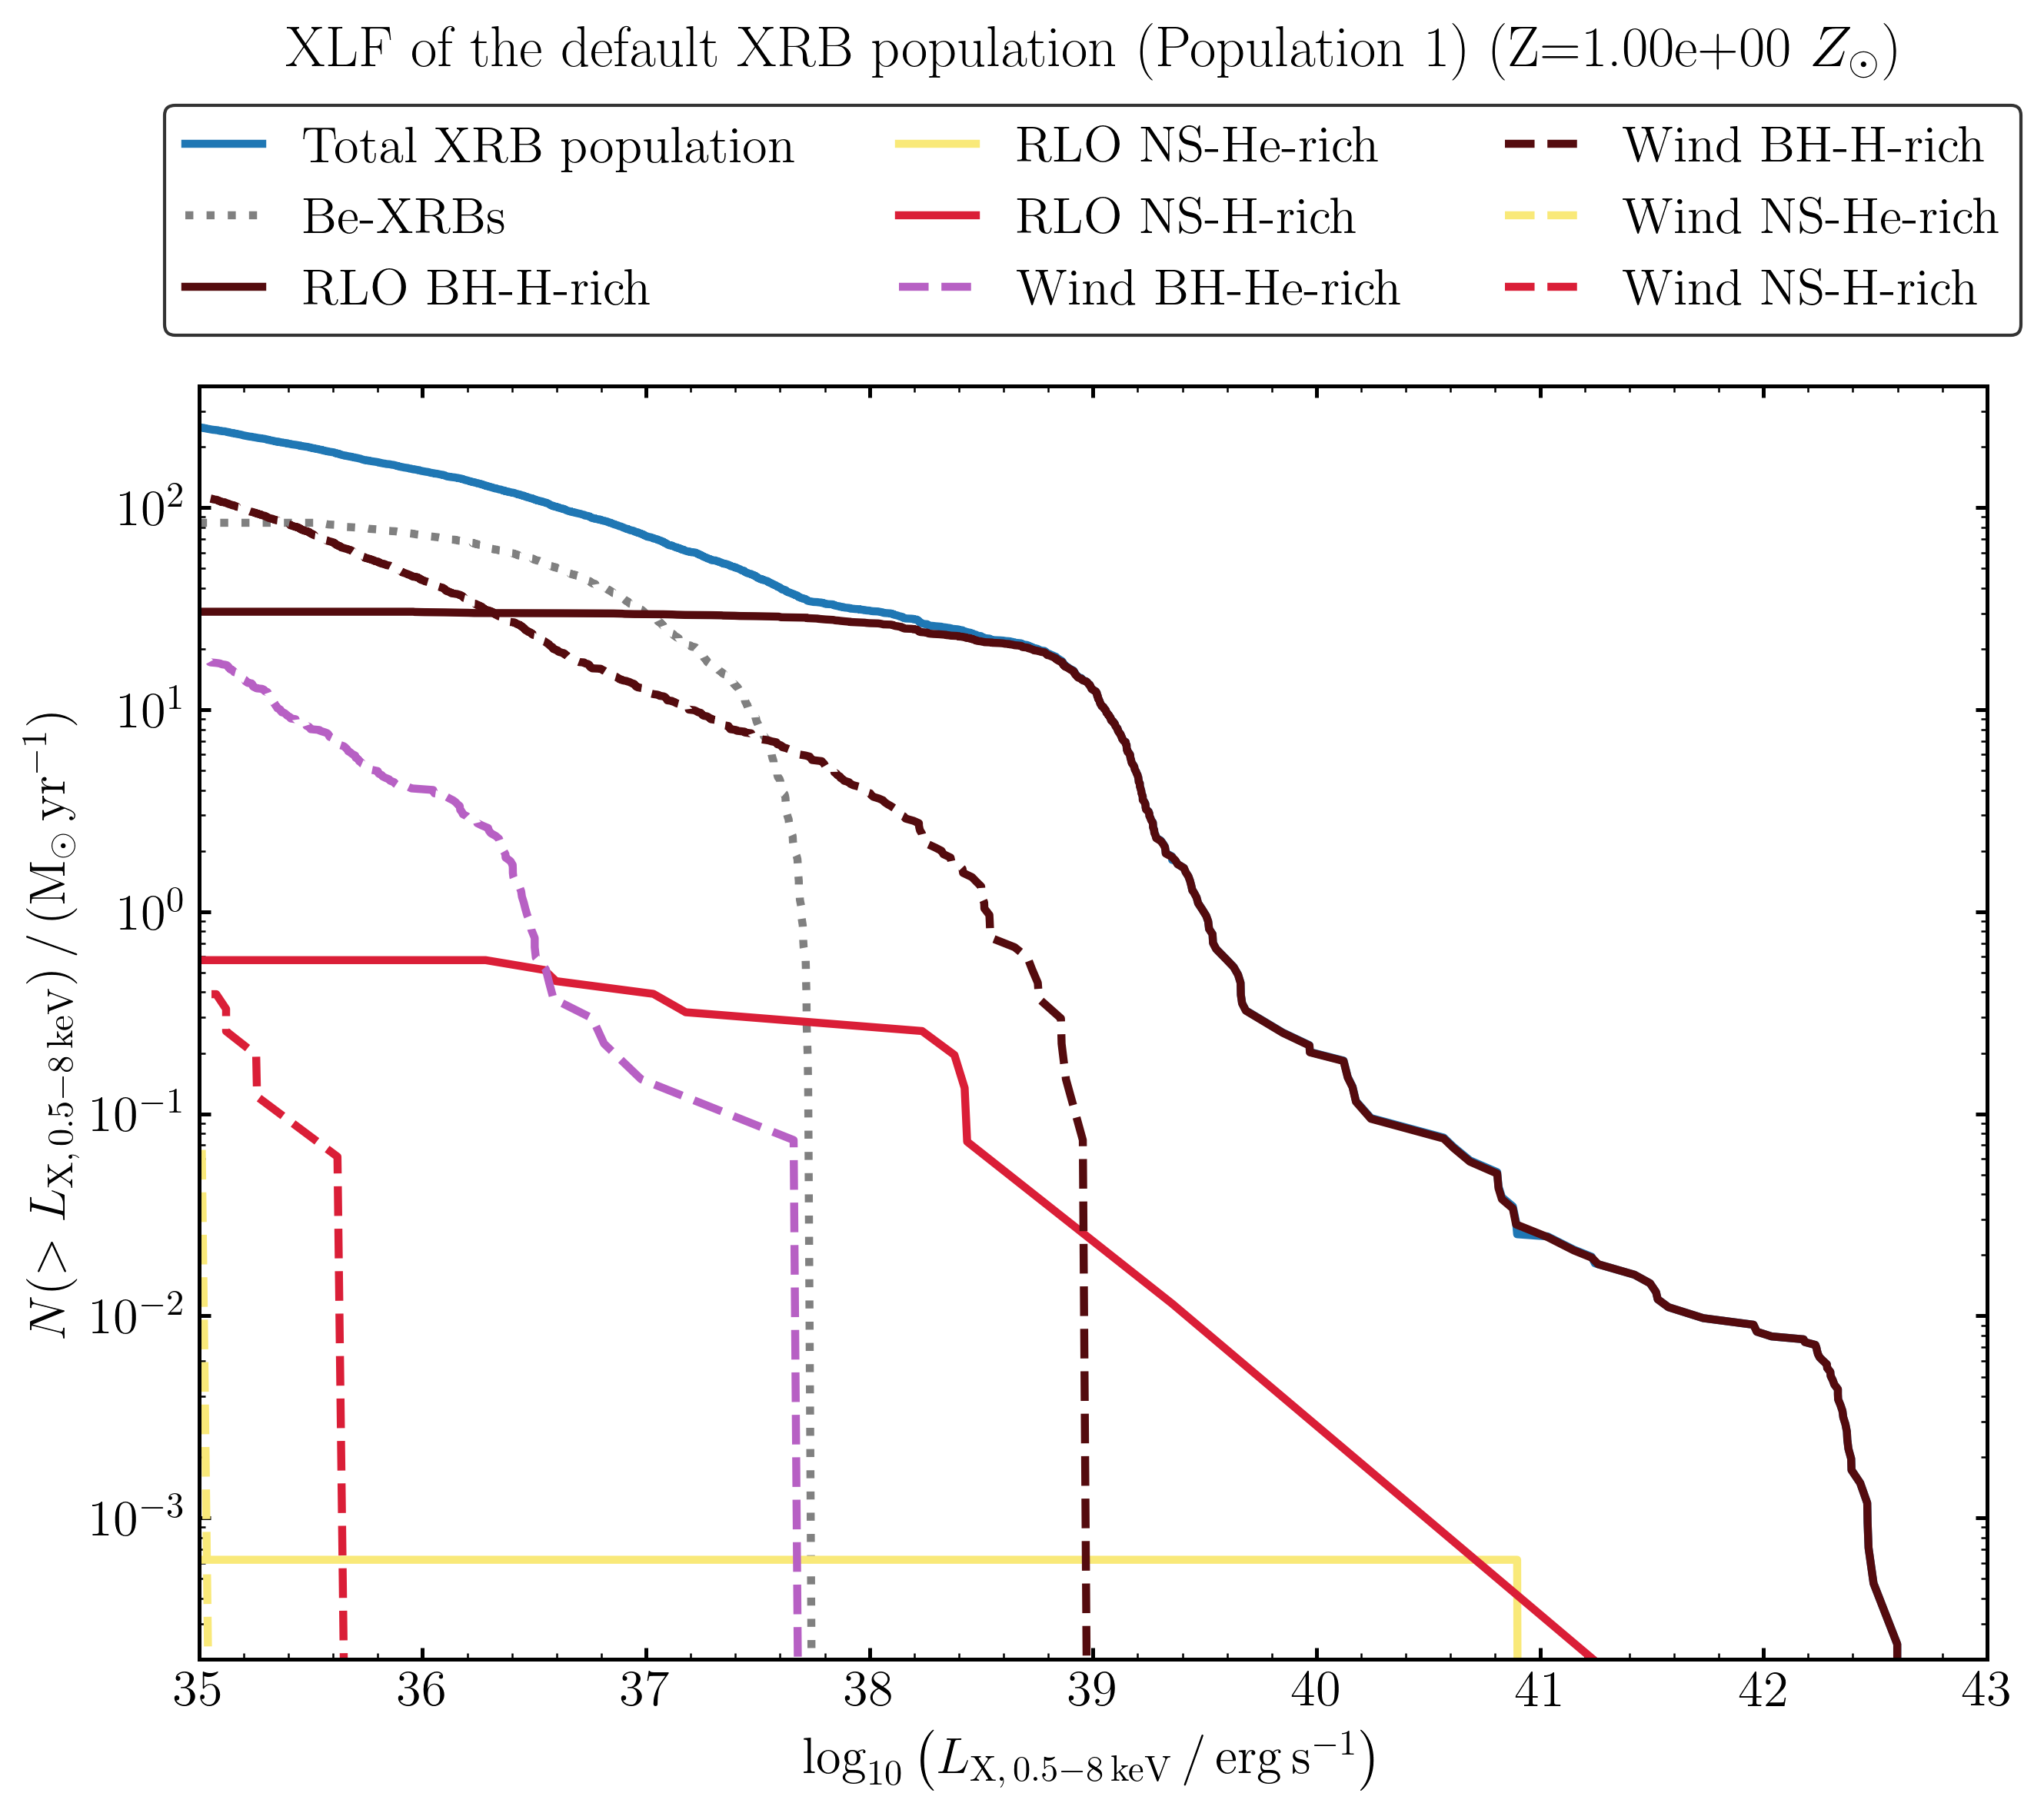

In [85]:

Plot_cumulative_XLF(Trans_pop, Weights, title = 'XLF of the default XRB population (Population 1)', linewidth=2.5)

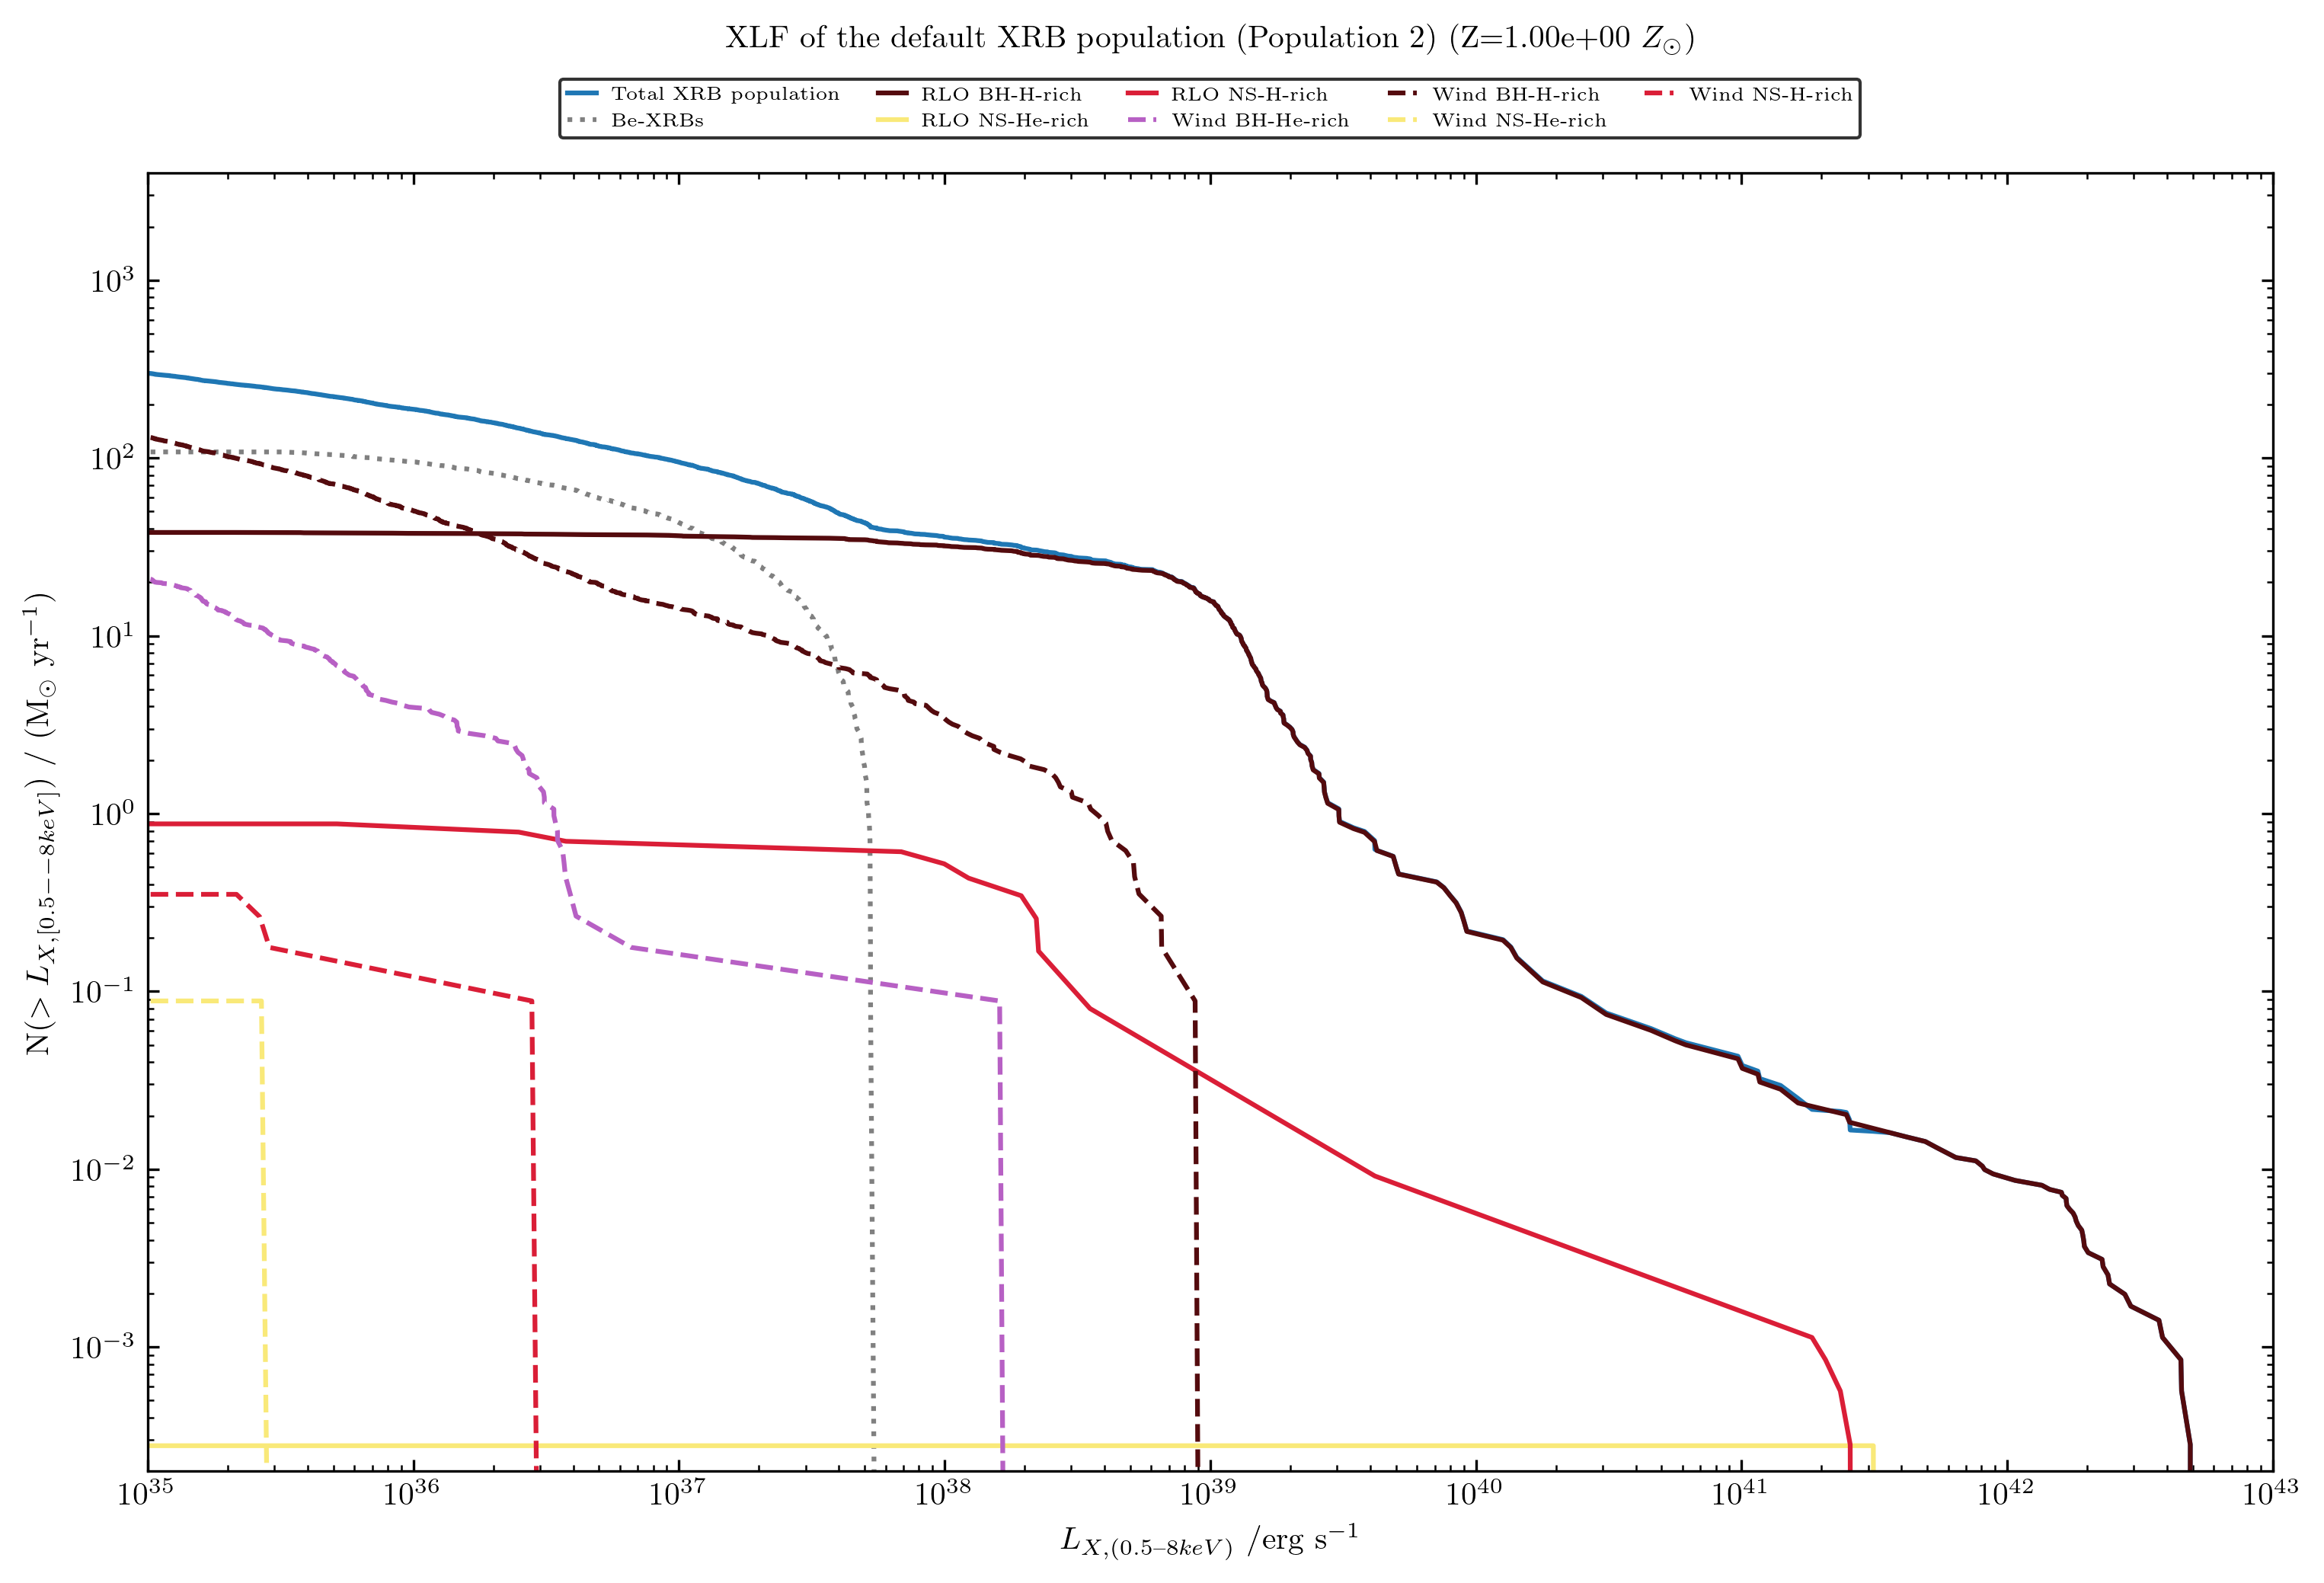

In [26]:
Plot_cumulative_XLF(Trans_pop2, Weights2, title = 'XLF of the default XRB population (Population 2)')

- Wind-NS-He-rich systems

In [16]:
Trans_pop.population.loc[(Trans_pop.population['System_type'] == 'Wind') & (Trans_pop.population['Accretor_state'] == 'NS') & Trans_pop.population['Donor_state'].str.contains('stripped_He', regex=True, na=False) & Trans_pop.population['Lx'].between(1e35, 1e43)]

,metallicity,time,Binary_state,Accretor_state,Accretor spin,Accretor_mass,Accretor_LogR,Donor_state,Donor_mass,Donor_LogR,...,Donor_He_Core_mass,Accretor_LogMdot,Donor_LogMdot,Orbital_separation,Eccentricity,System_type,Beaming,Eddington_state,Lx,formation_channel
binary_index,,,,,,,,,,,,,,,,,,,,,
18133,1.0,100000000.0,detached,NS,0.000213,1.196034,-4.745687,stripped_He_Core_He_depleted,1.870366,0.260528,...,1.870366,-10.764498,-6.470935,3.087194e+11,0.000000,Wind,1.0,Sub-Eddington,1.377161e+35,ZAMS_oRLO1_CC1_oRLO2_oCE2_maxtime_END
69121,1.0,100000000.0,detached,NS,0.000000,1.317117,-4.745687,stripped_He_Core_He_burning,9.666322,-0.028014,...,9.666322,-99.000000,-5.244067,8.949490e+11,0.586247,Wind,1.0,Sub-Eddington,1.927790e+36,ZAMS_oRLO1-reverse_CC1_maxtime_END


In [56]:
Trans_pop.history[[18133, 69121]]

,state,event,time,orbital_period,eccentricity,lg_mtransfer_rate,step_names,step_times,S1_state,S1_mass,...,S2_he_core_mass,S2_he_core_radius,S2_co_core_mass,S2_co_core_radius,S2_center_h1,S2_center_he4,S2_surface_h1,S2_surface_he4,S2_surf_avg_omega_div_omega_crit,S2_spin
binary_index,,,,,,,,,,,,,,,,,,,,,
18133,detached,ZAMS,3.357015e+07,159.677912,0.000000,NaN,initial_cond,0.000000,H-rich_Core_H_burning,7.830206,...,0.000000,NaN,NaN,NaN,7.155000e-01,2.703000e-01,NaN,NaN,NaN,NaN
18133,detached,CC1,7.992998e+07,643.632613,0.000000,-54.453006,step_HMS_HMS,0.081658,H-rich_Core_C_depleted,2.326295,...,0.000000,0.000000,0.000000,0.000000,3.636298e-01,6.225055e-01,6.995023e-01,0.286282,0.975852,14.819536
18133,detached,NaN,7.992998e+07,1271.195274,0.554872,NaN,step_SN,0.000349,NS,1.299228,...,0.000000,0.000000,0.000000,0.000000,3.636298e-01,6.225055e-01,6.995023e-01,0.286282,0.975852,14.819536
18133,RLO2,oRLO2,9.635046e+07,487.161041,0.000000,NaN,step_detached,0.437239,NS,1.299228,...,1.424293,NaN,0.000000,0.000000,1.826033e-31,9.844004e-01,7.144238e-01,0.271230,0.381106,165.707928
18133,RLO2,oCE2,9.635375e+07,388.465137,0.000000,-1.294769,step_CO_HMS_RLO,0.054246,NS,1.299303,...,1.895457,0.316016,0.684414,0.032774,0.000000e+00,2.714776e-12,6.976814e-01,0.288173,0.290843,121.689613
18133,detached,NaN,9.635375e+07,0.673712,0.000000,NaN,step_CE,0.000135,NS,1.299303,...,1.895457,0.316016,0.684414,0.032774,0.000000e+00,2.714776e-12,1.000000e-02,0.975800,NaN,NaN
18133,detached,NaN,9.635375e+07,0.561443,0.000000,-99.000000,step_CO_HeMS,0.090615,NS,1.196033,...,2.027697,0.342798,0.000000,0.000000,4.559784e-28,9.857973e-01,8.299830e-100,0.985800,0.000000,0.000000
18133,detached,maxtime,1.000000e+08,0.618239,0.000000,-10.769150,NaN,NaN,NS,1.196034,...,1.870366,1.825182,0.996432,0.039221,0.000000e+00,2.204157e-15,2.466177e-54,0.985800,0.175142,0.568926
18133,detached,END,1.000000e+08,0.618239,0.000000,-10.769150,step_end,0.000035,NS,1.196034,...,1.870366,1.825182,0.996432,0.039221,0.000000e+00,2.204157e-15,2.466177e-54,0.985800,0.175142,0.568926


- RLO-NS-He-rich systems

In [11]:
Trans_pop.population.loc[(Trans_pop.population['System_type'] == 'RLO') & (Trans_pop.population['Accretor_state'] == 'NS') & Trans_pop.population['Donor_state'].str.contains('stripped_He', regex=True, na=False) & Trans_pop.population['Lx'].between(1e35, 1e43)]

,metallicity,time,Binary_state,Accretor_state,Accretor spin,Accretor_mass,Accretor_LogR,Donor_state,Donor_mass,Donor_LogR,...,Donor_He_Core_mass,Accretor_LogMdot,Donor_LogMdot,Orbital_separation,Eccentricity,System_type,Beaming,Eddington_state,Lx,formation_channel
binary_index,,,,,,,,,,,,,,,,,,,,,
40525,1.0,100000000.0,RLO2,NS,0.004641,1.197514,-4.745687,stripped_He_Core_He_depleted,1.421474,-0.030779,...,1.421474,-7.427656,-4.943235,1.561714e+11,0.0,RLO,0.0032,Super-Eddington,6.269883e+41,ZAMS_oRLO1_CC1_oRLO2_oCE2_maxtime_END


- Wind-BH systems

In [40]:
Trans_pop.population[(Trans_pop.population['System_type'] == 'Wind')
                     & (Trans_pop.population['Accretor_state'] == 'BH')
                     & (Trans_pop.population['Accretor_LogMdot'] > -99)]

,metallicity,time,Binary_state,Accretor_state,Accretor spin,Accretor_mass,Accretor_LogR,Donor_state,Donor_mass,Donor_LogR,...,Donor_He_Core_mass,Accretor_LogMdot,Donor_LogMdot,Orbital_separation,Eccentricity,System_type,Beaming,Eddington_state,Lx,formation_channel
binary_index,,,,,,,,,,,,,,,,,,,,,
15,1.0,100000000.0,detached,BH,0.040150,12.274804,-4.283111,H-rich_Core_He_burning,11.918215,0.200514,...,11.199745,-98.698970,-5.228051,6.436782e+12,0.000000,Wind,1.0,Sub-Eddington,8.911347e+35,ZAMS_oRLO1_CC1_oRLO2_maxtime_END
69,1.0,100000000.0,detached,BH,0.123499,12.296781,-4.282334,H-rich_Core_He_burning,3.100533,0.469058,...,2.739221,-98.698970,-7.648824,1.225654e+14,0.000000,Wind,1.0,Sub-Eddington,1.307112e+31,ZAMS_CC1_oRLO2_maxtime_END
121,1.0,100000000.0,detached,BH,0.000272,16.812044,-4.146505,H-rich_Core_He_burning,9.668789,2.686465,...,3.667434,-9.315286,-6.041775,7.507495e+14,0.704677,Wind,1.0,Sub-Eddington,1.244622e+36,ZAMS_CC1_maxtime_END
163,1.0,100000000.0,detached,BH,0.026240,8.579193,-4.438679,H-rich_Core_He_burning,11.944436,0.299878,...,10.991855,-98.698970,-5.162423,3.226428e+12,0.000000,Wind,1.0,Sub-Eddington,1.785825e+36,ZAMS_oRLO1_CC1_oRLO2_maxtime_END
213,1.0,100000000.0,detached,BH,0.142965,12.260957,-4.283601,stripped_He_Core_He_burning,21.991741,0.172675,...,21.991705,-98.698970,-4.458450,2.016199e+13,0.000000,Wind,1.0,Sub-Eddington,1.809806e+35,ZAMS_CC1_oRLO2_maxtime_END
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82594,1.0,100000000.0,detached,BH,0.005881,8.572414,-4.439022,stripped_He_Core_He_burning,7.218234,-0.093205,...,7.218234,-98.698970,-5.447727,8.003748e+12,0.000000,Wind,1.0,Sub-Eddington,1.104286e+35,ZAMS_oRLO1_CC1_oRLO2_maxtime_END
82653,1.0,100000000.0,detached,BH,0.037708,17.544097,-4.127994,H-rich_Core_He_burning,6.095288,0.911448,...,5.137545,-96.682736,-5.794330,2.710821e+13,0.000000,Wind,1.0,Sub-Eddington,8.379455e+33,ZAMS_oRLO1_CC1_oRLO2_maxtime_END
82673,1.0,100000000.0,detached,BH,0.077914,10.259331,-4.361006,H-rich_Core_H_burning,14.431717,0.924750,...,0.000000,-98.698970,-6.234989,1.453476e+12,0.000000,Wind,1.0,Sub-Eddington,5.720676e+35,ZAMS_oRLO1_CC1_oRLO2_maxtime_END


#### Population with GRMHD

In [7]:
selection1e_02 = Population('Pop_with_GRMHD/BHNS_GRMHD_1e-02_Zsun.h5')
selection1e_04 = Population('Pop_with_GRMHD/BHNS_GRMHD_1e-04_Zsun.h5')


In [8]:
selection1e_02.calculate_formation_channels()
selection1e_04.calculate_formation_channels()

In [41]:
Trans_Pop_GRMHD_1e_02 = selection1e_02.create_transient_population(XRB_selection_function, 'GRMHD_1e_02_XRB_population')
Trans_Pop_GRMHD_1e_04 = selection1e_04.create_transient_population(XRB_selection_function, 'GRMHD_1e_04_XRB_population')

overwriting transient population
overwriting transient population


In [35]:
Weights2, _ = Stat_XLF(Trans_Pop_GRMHD_1e_02, stat_kwargs=stat_kwargs)
Weights4, _ = Stat_XLF(Trans_Pop_GRMHD_1e_04, stat_kwargs=stat_kwargs)

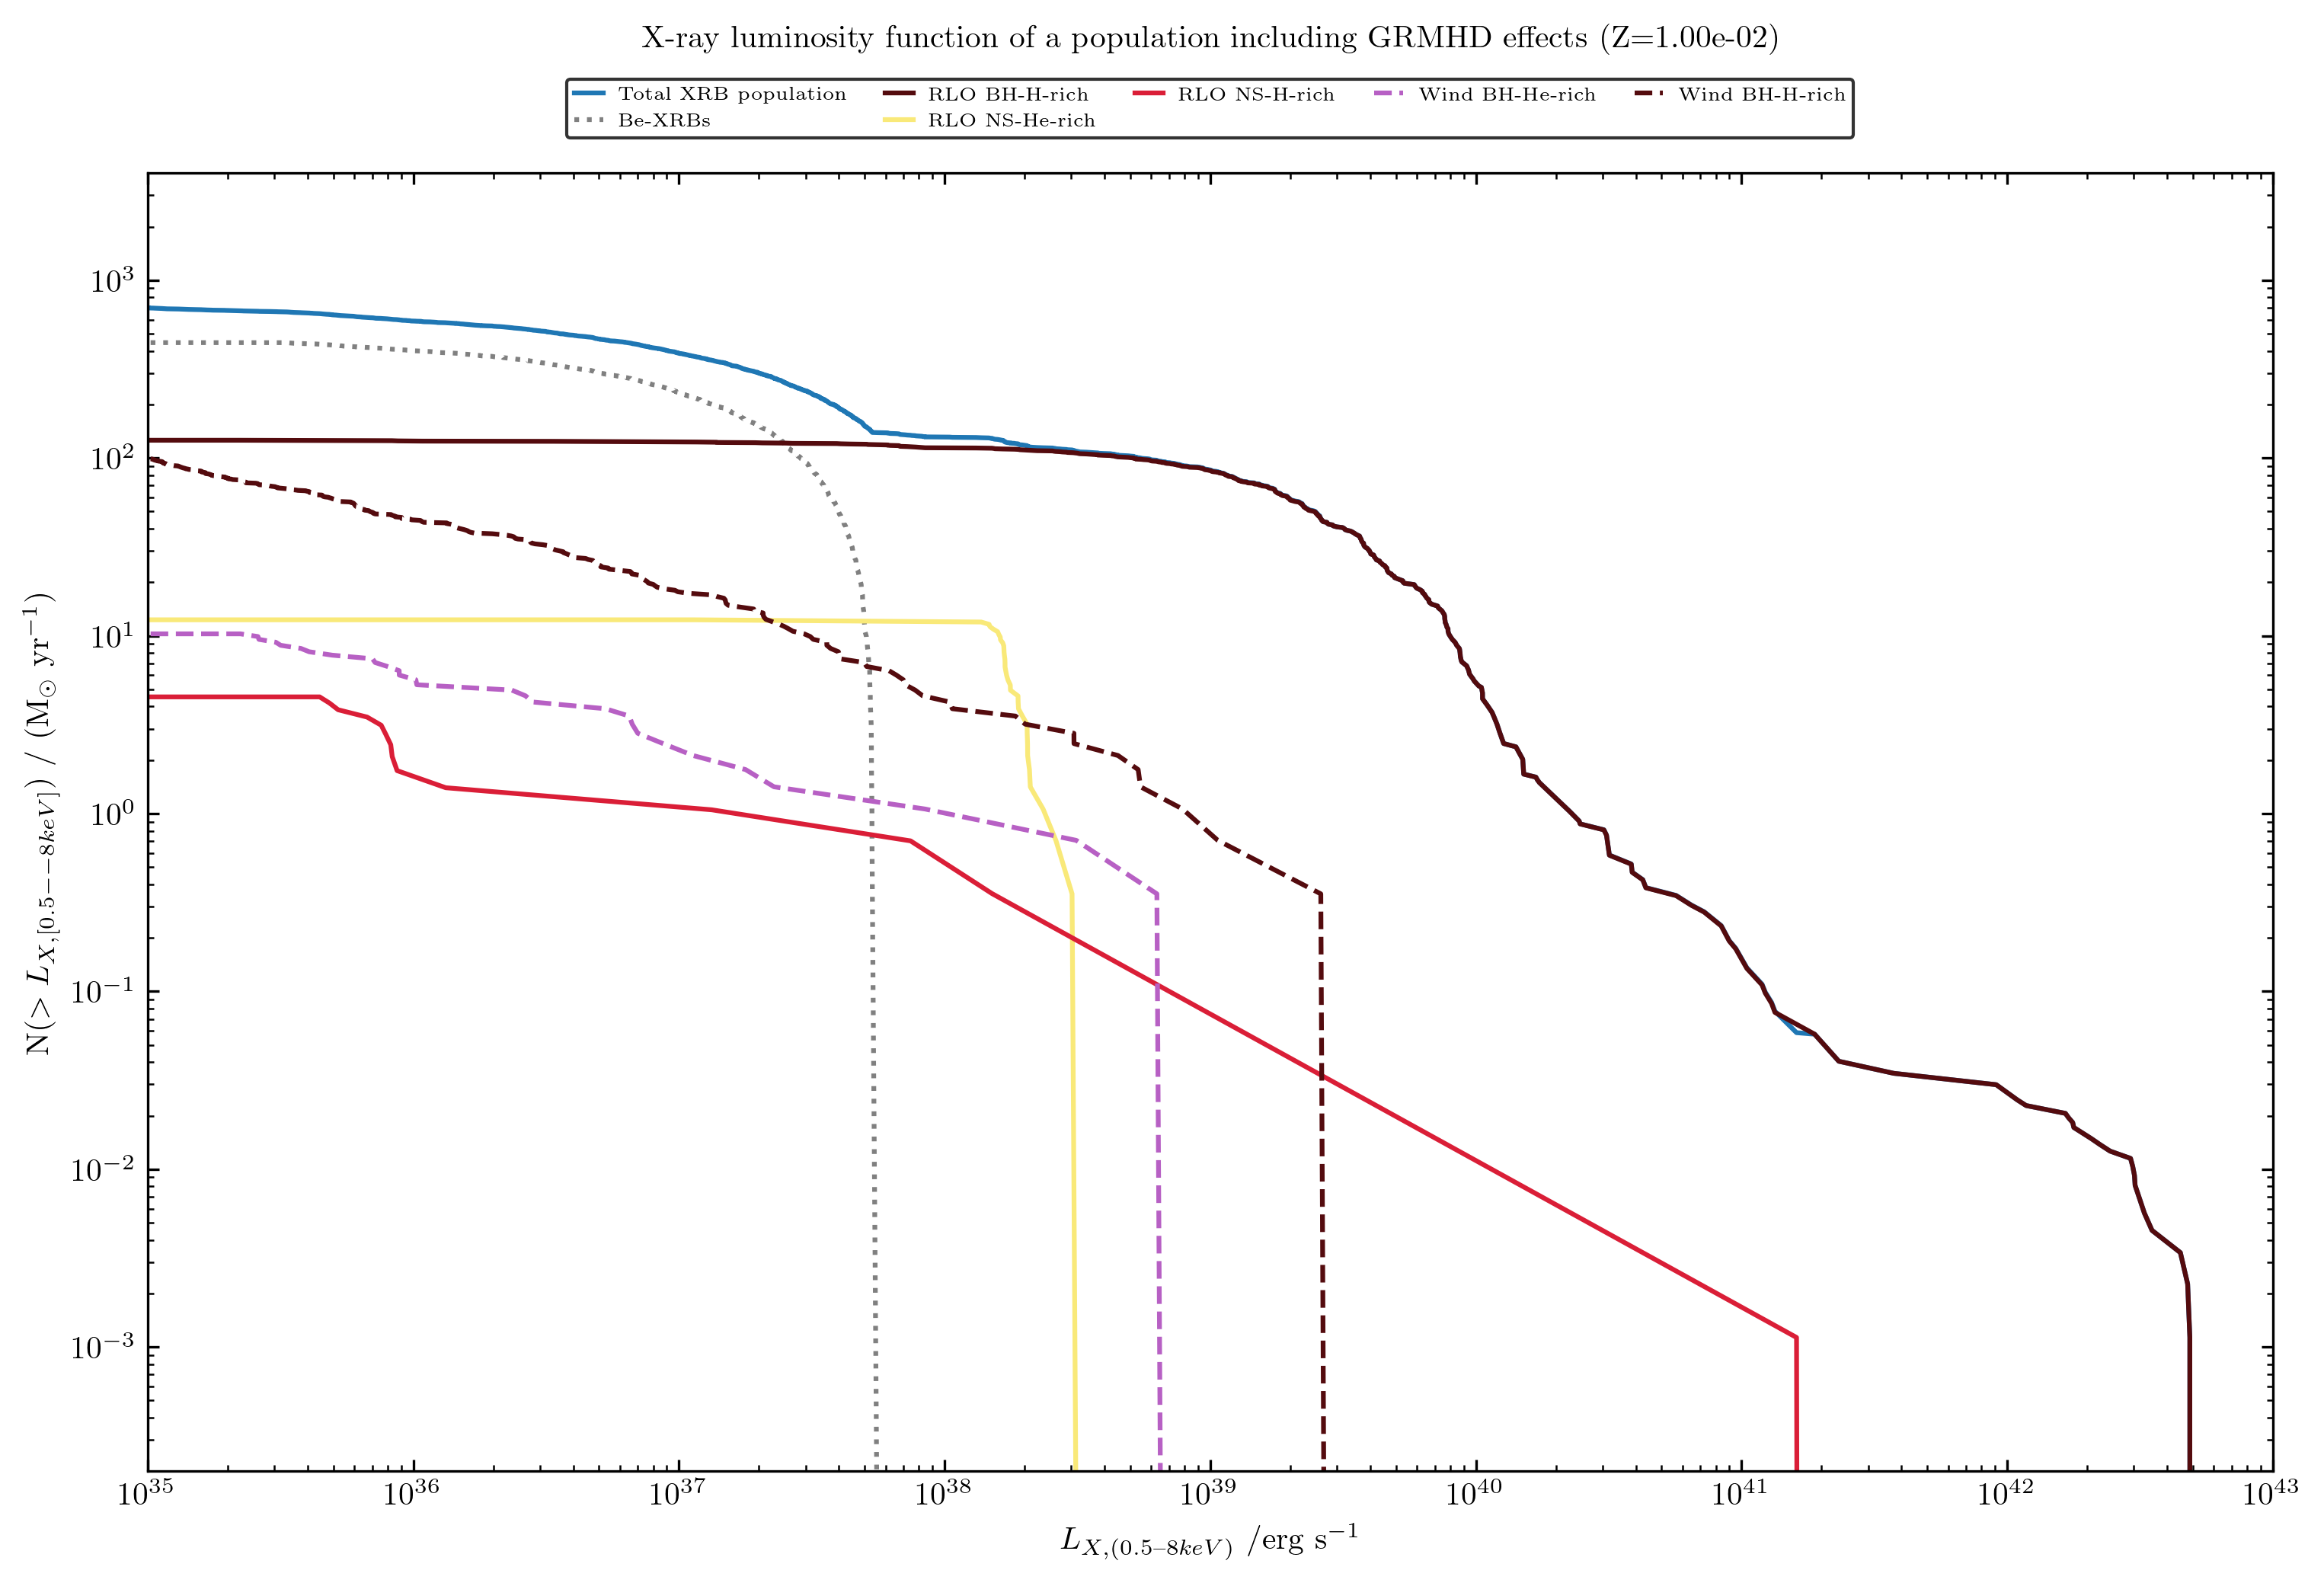

In [43]:
Plot_cumulative_XLF(Trans_Pop_GRMHD_1e_02, Weights2, title = 'X-ray luminosity function of a population including GRMHD effects')

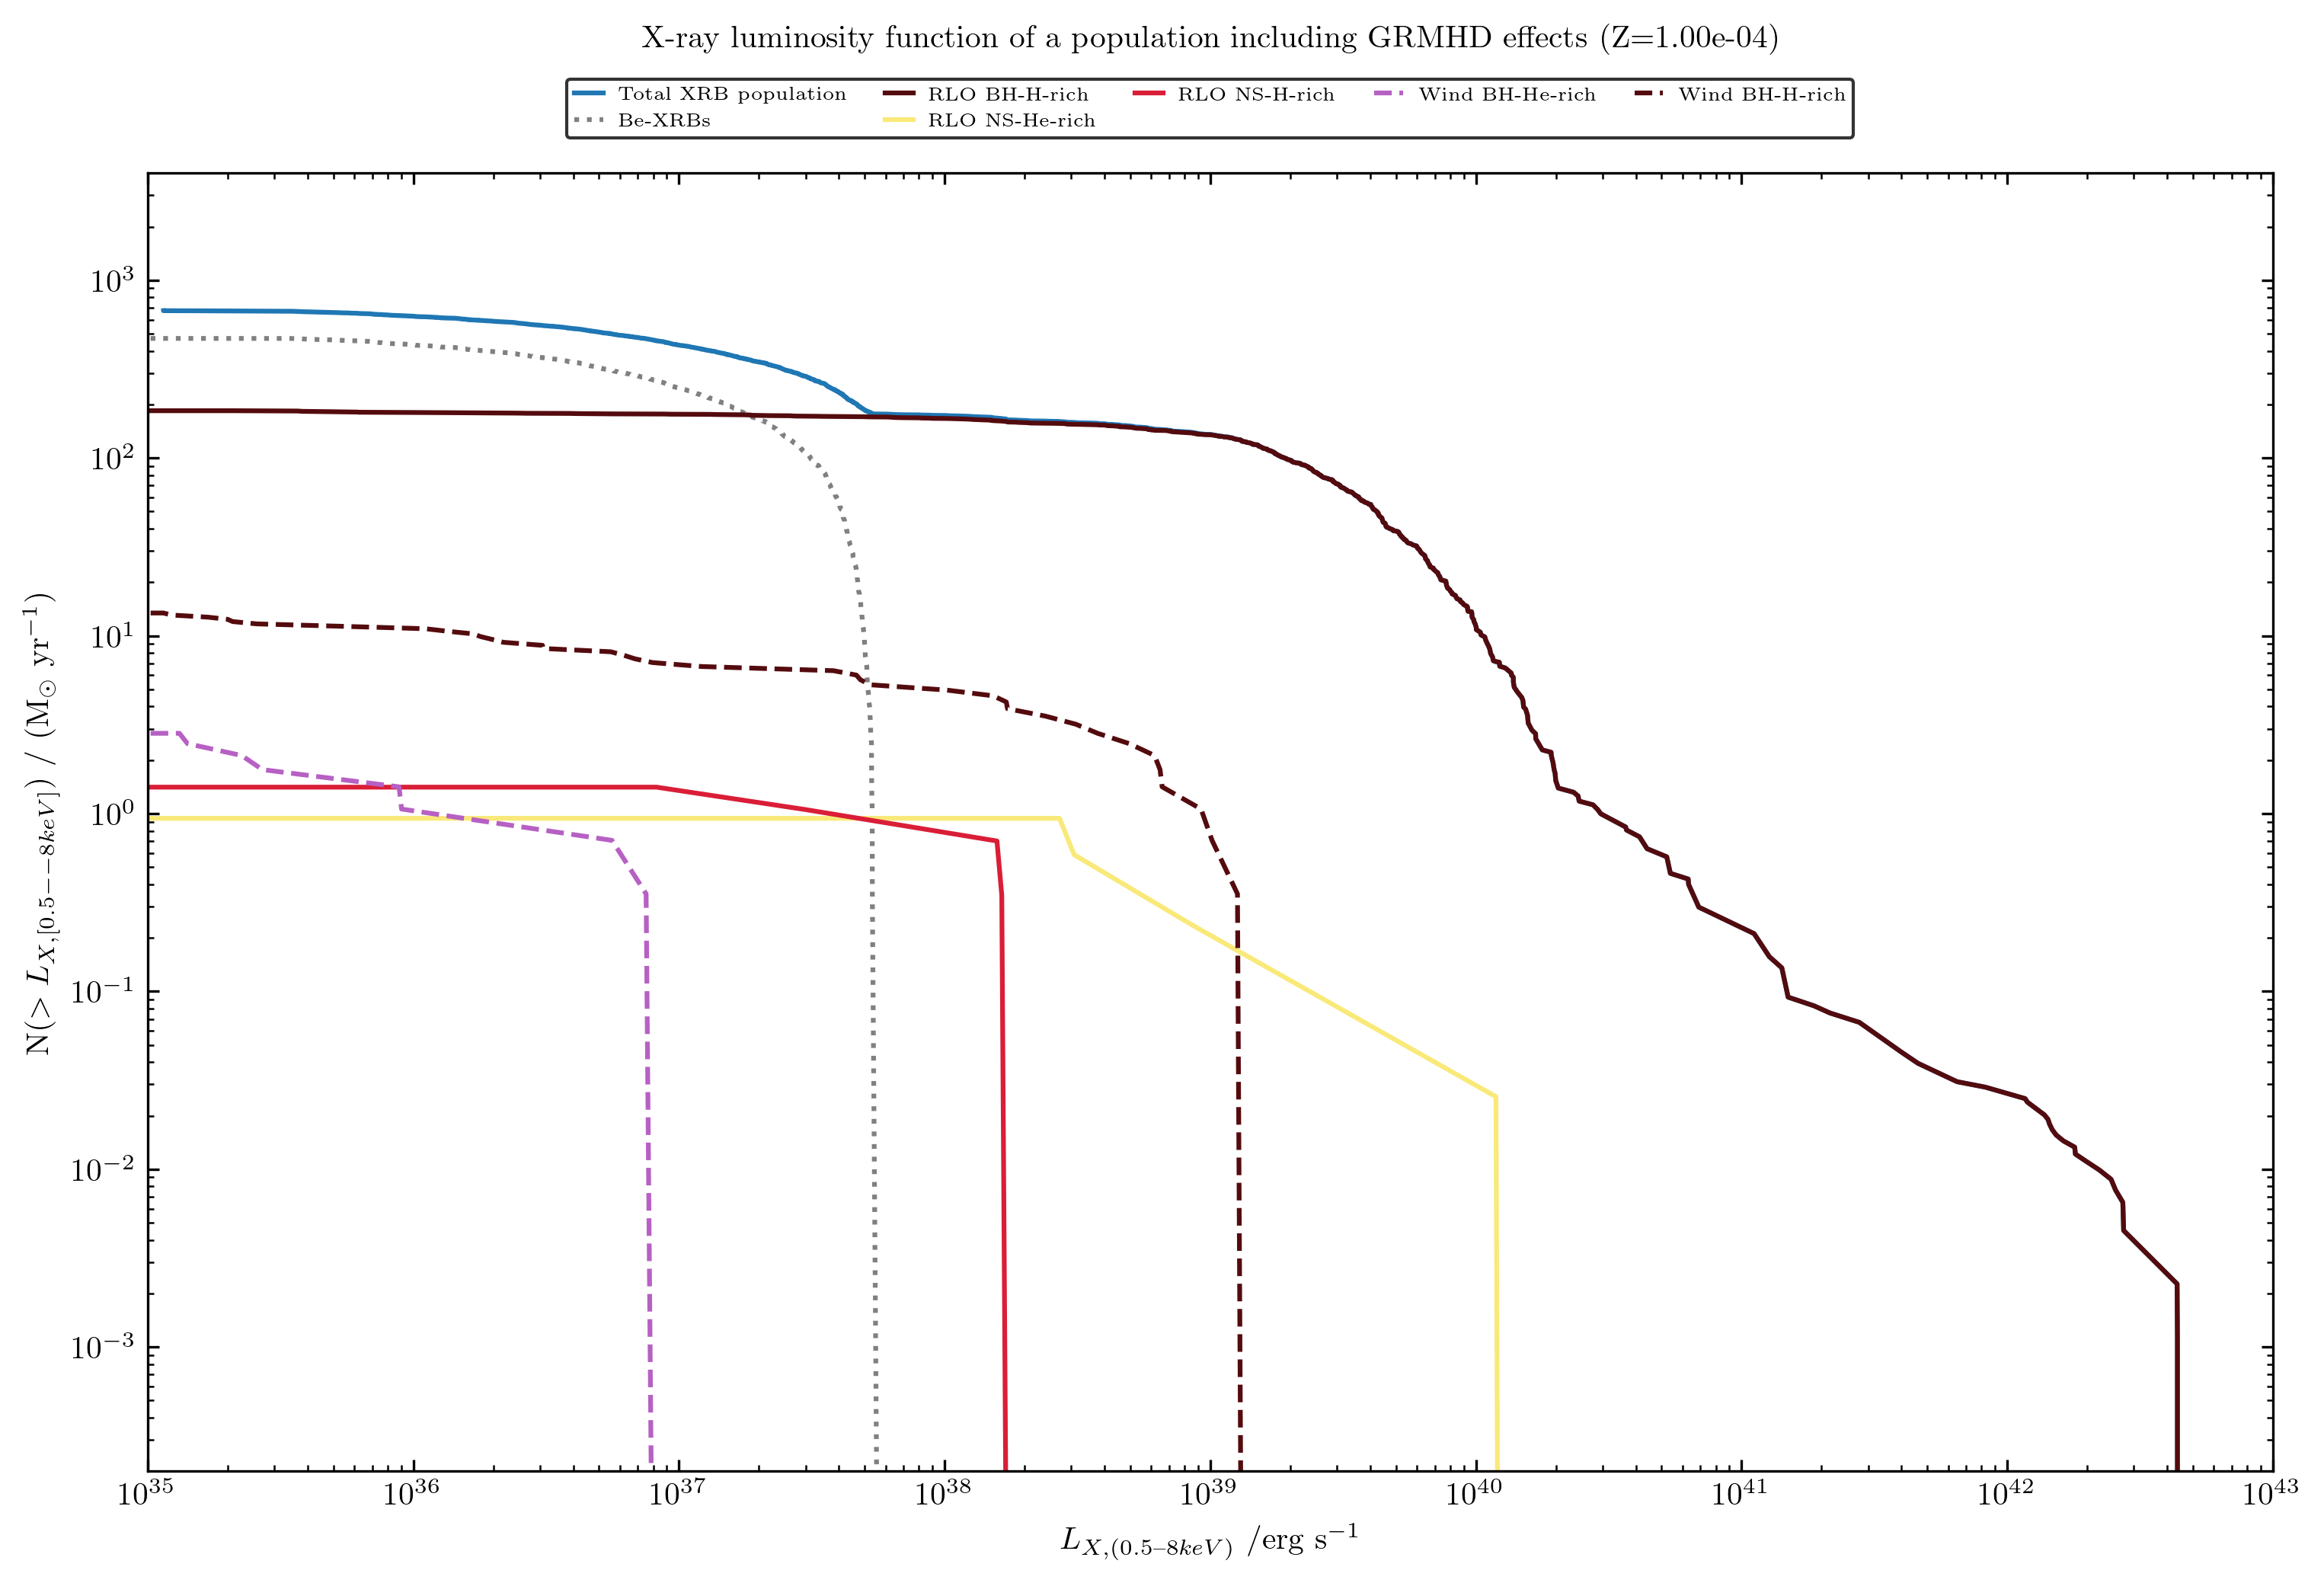

In [44]:
Plot_cumulative_XLF(Trans_Pop_GRMHD_1e_04, Weights4, title = 'X-ray luminosity function of a population including GRMHD effects')

- Wind-NS-He-rich 

In [26]:
Trans_Pop_GRMHD_1e_04.population.loc[(Trans_Pop_GRMHD_1e_04.population['System_type'] == 'Wind') & (Trans_Pop_GRMHD_1e_04.population['Accretor_state'] == 'NS') & Trans_Pop_GRMHD_1e_04.population['Donor_state'].str.contains('stripped_He', regex=True, na=False) & Trans_Pop_GRMHD_1e_04.population['Lx'].between(1e35, 1e43)]

,metallicity,time,lg_mtransfer_rate,Binary_state,Accretor_state,Accretor spin,Accretor_mass,Accretor_LogR,Donor_state,Donor_mass,...,Donor_He_Core_mass,Accretor_LogMdot,Donor_LogMdot_wind,Orbital_separation,Eccentricity,System_type,Beaming,Eddington_state,Lx,formation_channel
binary_index,,,,,,,,,,,,,,,,,,,,,


### Without usung create_transient_population()

In [30]:
Final_df = XRB_selection_function(history_chunk=None, oneline_chunk=selection.oneline, formation_channels_chunk=selection.formation_channels)

In [24]:
Final_df

,Metallicity,Time,State_system,Accretor_state,Accretor spin,Accretor_mass,Accretor_LogR,Donor_state,Donor_mass,Donor_LogR,...,Donor_LogL,Donor_H1_at_surface,Donor_He_Core_mass,Accretor_LogMdot,Donor_LogMdot,Orbital_separation,Eccentricity,system_type,Eddington_state,Lx
binary_index,,,,,,,,,,,,,,,,,,,,,
278,1.0,100000000.0,RLO2,BH,0.611950,10.476137,-4.351941,H-rich_Core_H_burning,5.884450,0.885566,...,3.807023,0.714415,0.0,-6.519362,-6.506435,1.619784e+12,0.0,RLO,Super-Eddington,1.583012e+39
306,1.0,100000000.0,RLO2,BH,0.373752,9.437611,-4.397996,H-rich_Core_H_burning,7.494274,0.846253,...,3.898510,0.715037,0.0,-6.457024,-6.128838,1.373986e+12,0.0,RLO,Super-Eddington,2.466485e+39
427,1.0,100000000.0,RLO2,BH,0.256326,16.141468,-4.166191,H-rich_Core_H_burning,8.966002,0.872940,...,4.041549,0.715235,0.0,-6.222788,-6.185020,1.662892e+12,0.0,RLO,Super-Eddington,2.400726e+39
525,1.0,100000000.0,RLO2,BH,0.166714,15.096131,-4.193261,H-rich_Core_H_burning,19.680645,1.089469,...,5.429174,0.444096,0.0,-6.118735,-5.449547,2.127520e+12,0.0,RLO,Super-Eddington,2.874279e+39
794,1.0,100000000.0,RLO2,NS,0.000441,1.430730,-4.745687,H-rich_Core_H_burning,6.263602,0.580914,...,3.223915,0.715491,0.0,-7.757732,-7.670120,5.206890e+11,0.0,RLO,Sub-Eddington,1.993727e+38
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82303,NaN,NaN,Be system,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Be,NaN,2.502326e+37
82542,NaN,NaN,Be system,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Be,NaN,1.076359e+36
82584,NaN,NaN,Be system,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Be,NaN,3.103893e+37


In [12]:
H1_rich_RLO = (Final_df['System_type'] == 'RLO') & Final_df['Donor_state'].str.contains('H-rich|accreted_He', regex=True, na=False)
stripped_He_RLO = (Final_df['System_type'] == 'RLO') & Final_df['Donor_state'].str.contains('stripped_He', na=False)
BH_RLO = (Final_df['System_type'] == 'RLO') & (Final_df['Accretor_state'] == 'BH')
NS_RLO = (Final_df['System_type'] == 'RLO') & (Final_df['Accretor_state'] == 'NS')

H1_rich_Wind = (Final_df['System_type'] == 'Wind') & Final_df['Donor_state'].str.contains('H-rich|accreted_He', regex=True, na=False)
stripped_He_Wind = (Final_df['System_type'] == 'Wind') & Final_df['Donor_state'].str.contains('stripped_He', na=False)
BH_Wind = (Final_df['System_type'] == 'Wind') & (Final_df['Accretor_state'] == 'BH')
NS_Wind = (Final_df['System_type'] == 'Wind') & (Final_df['Accretor_state'] == 'NS')

Be_sys = Final_df['Binary_state'] == 'Be system'
Lx_Total = Final_df['Lx']

NameError: name 'Final_df' is not defined

In [29]:
plt.figure(figsize=(6,5), dpi = 150)

h, bins = np.histogram(Final_df['Lx'][Be_sys], bins=np.logspace(35, 45, 1000))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', color = '#808080', label='Be-XRBs')

h, bins = np.histogram(Final_df['Lx'][BH_RLO & H1_rich_RLO], bins=np.logspace(35, 45, 1000))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'RLO-BH-H-rich', color ='#540B0E')

h, bins = np.histogram(Final_df['Lx'][NS_RLO & H1_rich_RLO], bins=np.logspace(35, 45, 1000))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'RLO-NS-H-rich', color ='#DA1E37')

h, bins = np.histogram(Final_df['Lx'][BH_RLO & stripped_He_RLO], bins=np.logspace(35, 45, 10000))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'RLO-BH-stripped_He', color='#B760C4')
h, bins = np.histogram(Final_df['Lx'][stripped_He_RLO & NS_RLO], bins=np.logspace(35, 45, 1000))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'RLO-NS-stripped_He', color='#F9E979')

h, bins = np.histogram(Final_df['Lx'][BH_Wind & H1_rich_Wind], bins=np.logspace(35, 45, 1000))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'Wind-BH-H-rich', linestyle='--', color='#540B0E')

h, bins = np.histogram(Final_df['Lx'][NS_Wind & H1_rich_Wind], bins=np.logspace(35, 45, 1000))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'Wind-NS-H-rich', linestyle='--', color='#DA1E37')

h, bins = np.histogram(Final_df['Lx'][BH_Wind & stripped_He_Wind], bins=np.logspace(35, 45, 1000))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'Wind-BH-stripped_He', linestyle='--', color='#B760C4')

h, bins = np.histogram(Final_df['Lx'][NS_Wind & stripped_He_Wind], bins=np.logspace(35, 45, 1000))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'Wind-NS-stripped_He', linestyle='--', color='#F9E979')

h, bins = np.histogram(Lx_Total, bins=np.logspace(35, 45, 100))
h = np.cumsum(h[::-1])[::-1]
plt.step(bins[:-1], h, where='post', label = 'Total', color = '#1F77B4')

plt.xscale('log')
plt.yscale('log')
plt.xlim(1e35, 1e44)
plt.legend()

NameError: name 'Final_df' is not defined

<Figure size 900x750 with 0 Axes>

### Pop 55 & 64 with GRMHD

In [7]:
files = ['Pop_with_GRMHD/Best_Pop_with_GRMHD/Pop_55/1e+00_Zsun_population.h5',
         'Pop_with_GRMHD/Best_Pop_with_GRMHD/Pop_64/1e+00_Zsun_population.h5'
]

filenames = ['BHNS_55', 'BHNS_64']

Systems_selection_for_XRB(files, filenames)


Processing file Pop_with_GRMHD/Best_Pop_with_GRMHD/Pop_55/1e+00_Zsun_population.h5 in Population() ...
Exporting selected systems to Pop_with_GRMHD/Best_Pop_with_GRMHD/Pop_55/BHNS_55.h5 ...
Resume: 1e+00_Zsun_population.h5.
        Selection stored as Pop_with_GRMHD/Best_Pop_with_GRMHD/Pop_55/BHNS_55.h5 
        Number of selected systems : 21498.

Processing file Pop_with_GRMHD/Best_Pop_with_GRMHD/Pop_64/1e+00_Zsun_population.h5 in Population() ...
Exporting selected systems to Pop_with_GRMHD/Best_Pop_with_GRMHD/Pop_64/BHNS_64.h5 ...
Resume: 1e+00_Zsun_population.h5.
        Selection stored as Pop_with_GRMHD/Best_Pop_with_GRMHD/Pop_64/BHNS_64.h5 
        Number of selected systems : 20708.


In [7]:
#Pop_55 = Population('Pop_with_GRMHD/Best_Pop_with_GRMHD/Pop_55/BHNS_55.h5')
Pop_64 = Population('Pop_with_GRMHD/Best_Pop_with_GRMHD/Pop_64/BHNS_64.h5')

In [ ]:
#Pop_55.calculate_formation_channels(mt_history=True)
Pop_64.calculate_formation_channels(mt_history=True)

Formation channels already exist in the parsed population file!
Channels will be overwriten


In [20]:
#Trans_Pop_55 = Pop_55.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, Wind_Disk_BH_formation=True, high_wind_rate='HiraiMandel21'),'Transient_population_55')
Trans_Pop_64 = Pop_64.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, Wind_Disk_BH_formation=False, high_wind_rate='HiraiMandel21'),'Transient_population_64')

overwriting transient population


In [33]:
mask_RLO_BH_He_rich = (
                      (Trans_Pop_64.population['System_type'] == 'RLO') 
                    & (Trans_Pop_64.population['Accretor_state'] == 'BH') 
                    & (Trans_Pop_64.population['Donor_state'].str.contains('stripped_He', na=False))
                    )
Trans_Pop_64.population[mask_RLO_BH_He_rich]

,metallicity,time,lg_mtransfer_rate,Binary_state,Accretor_state,Accretor spin,Accretor_mass,Accretor_LogR,Donor_state,Donor_mass,...,Donor_He_Core_mass,Accretor_LogMdot,Donor_LogMdot_wind,Orbital_separation,Eccentricity,System_type,Beaming,Eddington_state,Lx,formation_channel
binary_index,,,,,,,,,,,,,,,,,,,,,


In [ ]:
#Weights_55 = Stat_XLF(Trans_Pop_55, stat_kwargs=stat_kwargs)
Weights_64 = Stat_XLF(Trans_Pop_64, stat_kwargs=stat_kwargs)

/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/tmp/ipykernel_2964975/2284827611.py:260: RuntimeWarning: divide by zero encountered in log10
/tmp/ipykernel_2964975/2284827611.py:260: RuntimeWarning: divide by zero encountered in log10
/tmp/ipykernel_2964975/2284827611.py:260: RuntimeWarning: divide by zero encountered in log10
/tmp/ipykernel_2964975/2284827611.py:260: RuntimeWarning: divide by zero encountered in log10
/tmp/ipykernel_2964975/2284827611.py:260: RuntimeWarning: divide by zero encountered in log10
/tmp/ipykernel_2964975/2284827611.py:260: RuntimeWarning: divide by zero encountered in log10
/tmp/ipykernel_2964975/2284827611.py:260: RuntimeWarning: divide by zero encountered in log10
/tmp/ipykernel_2964975/228

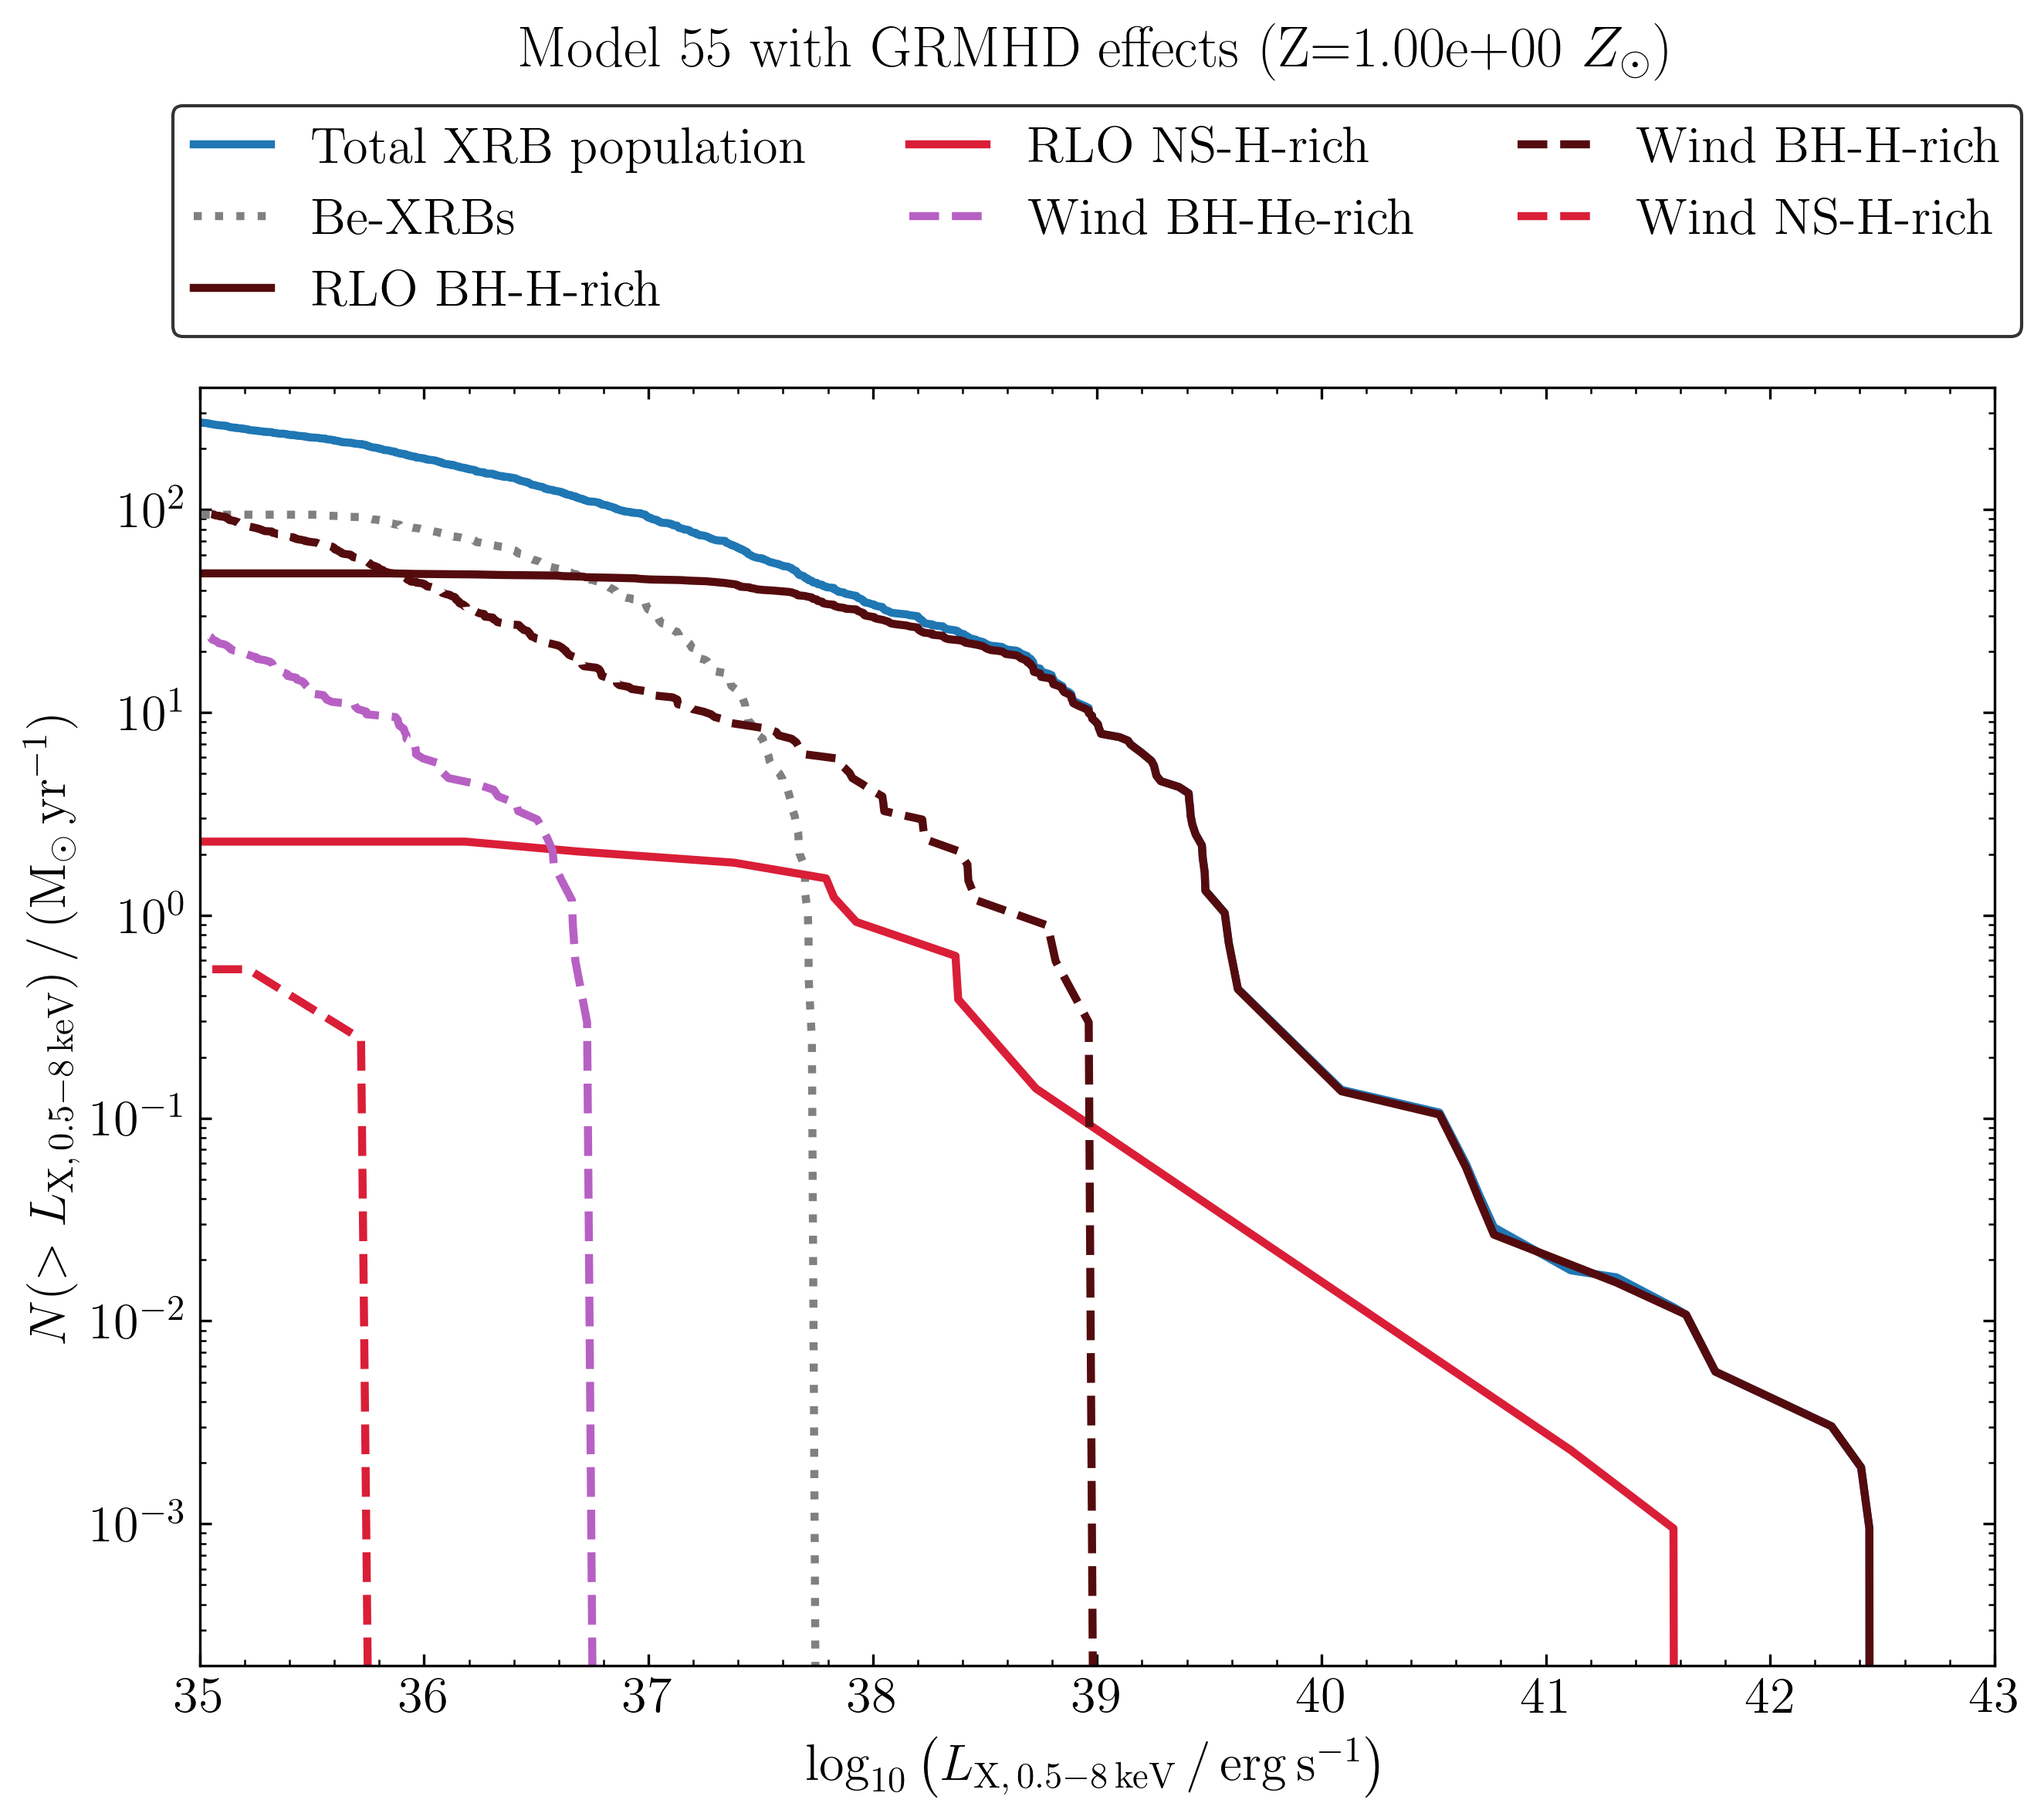

In [ ]:
#fig, ax = Plot_cumulative_XLF(Trans_Pop_55, Weights_55, title='Model 55 with GRMHD effects',linewidth=2.5)

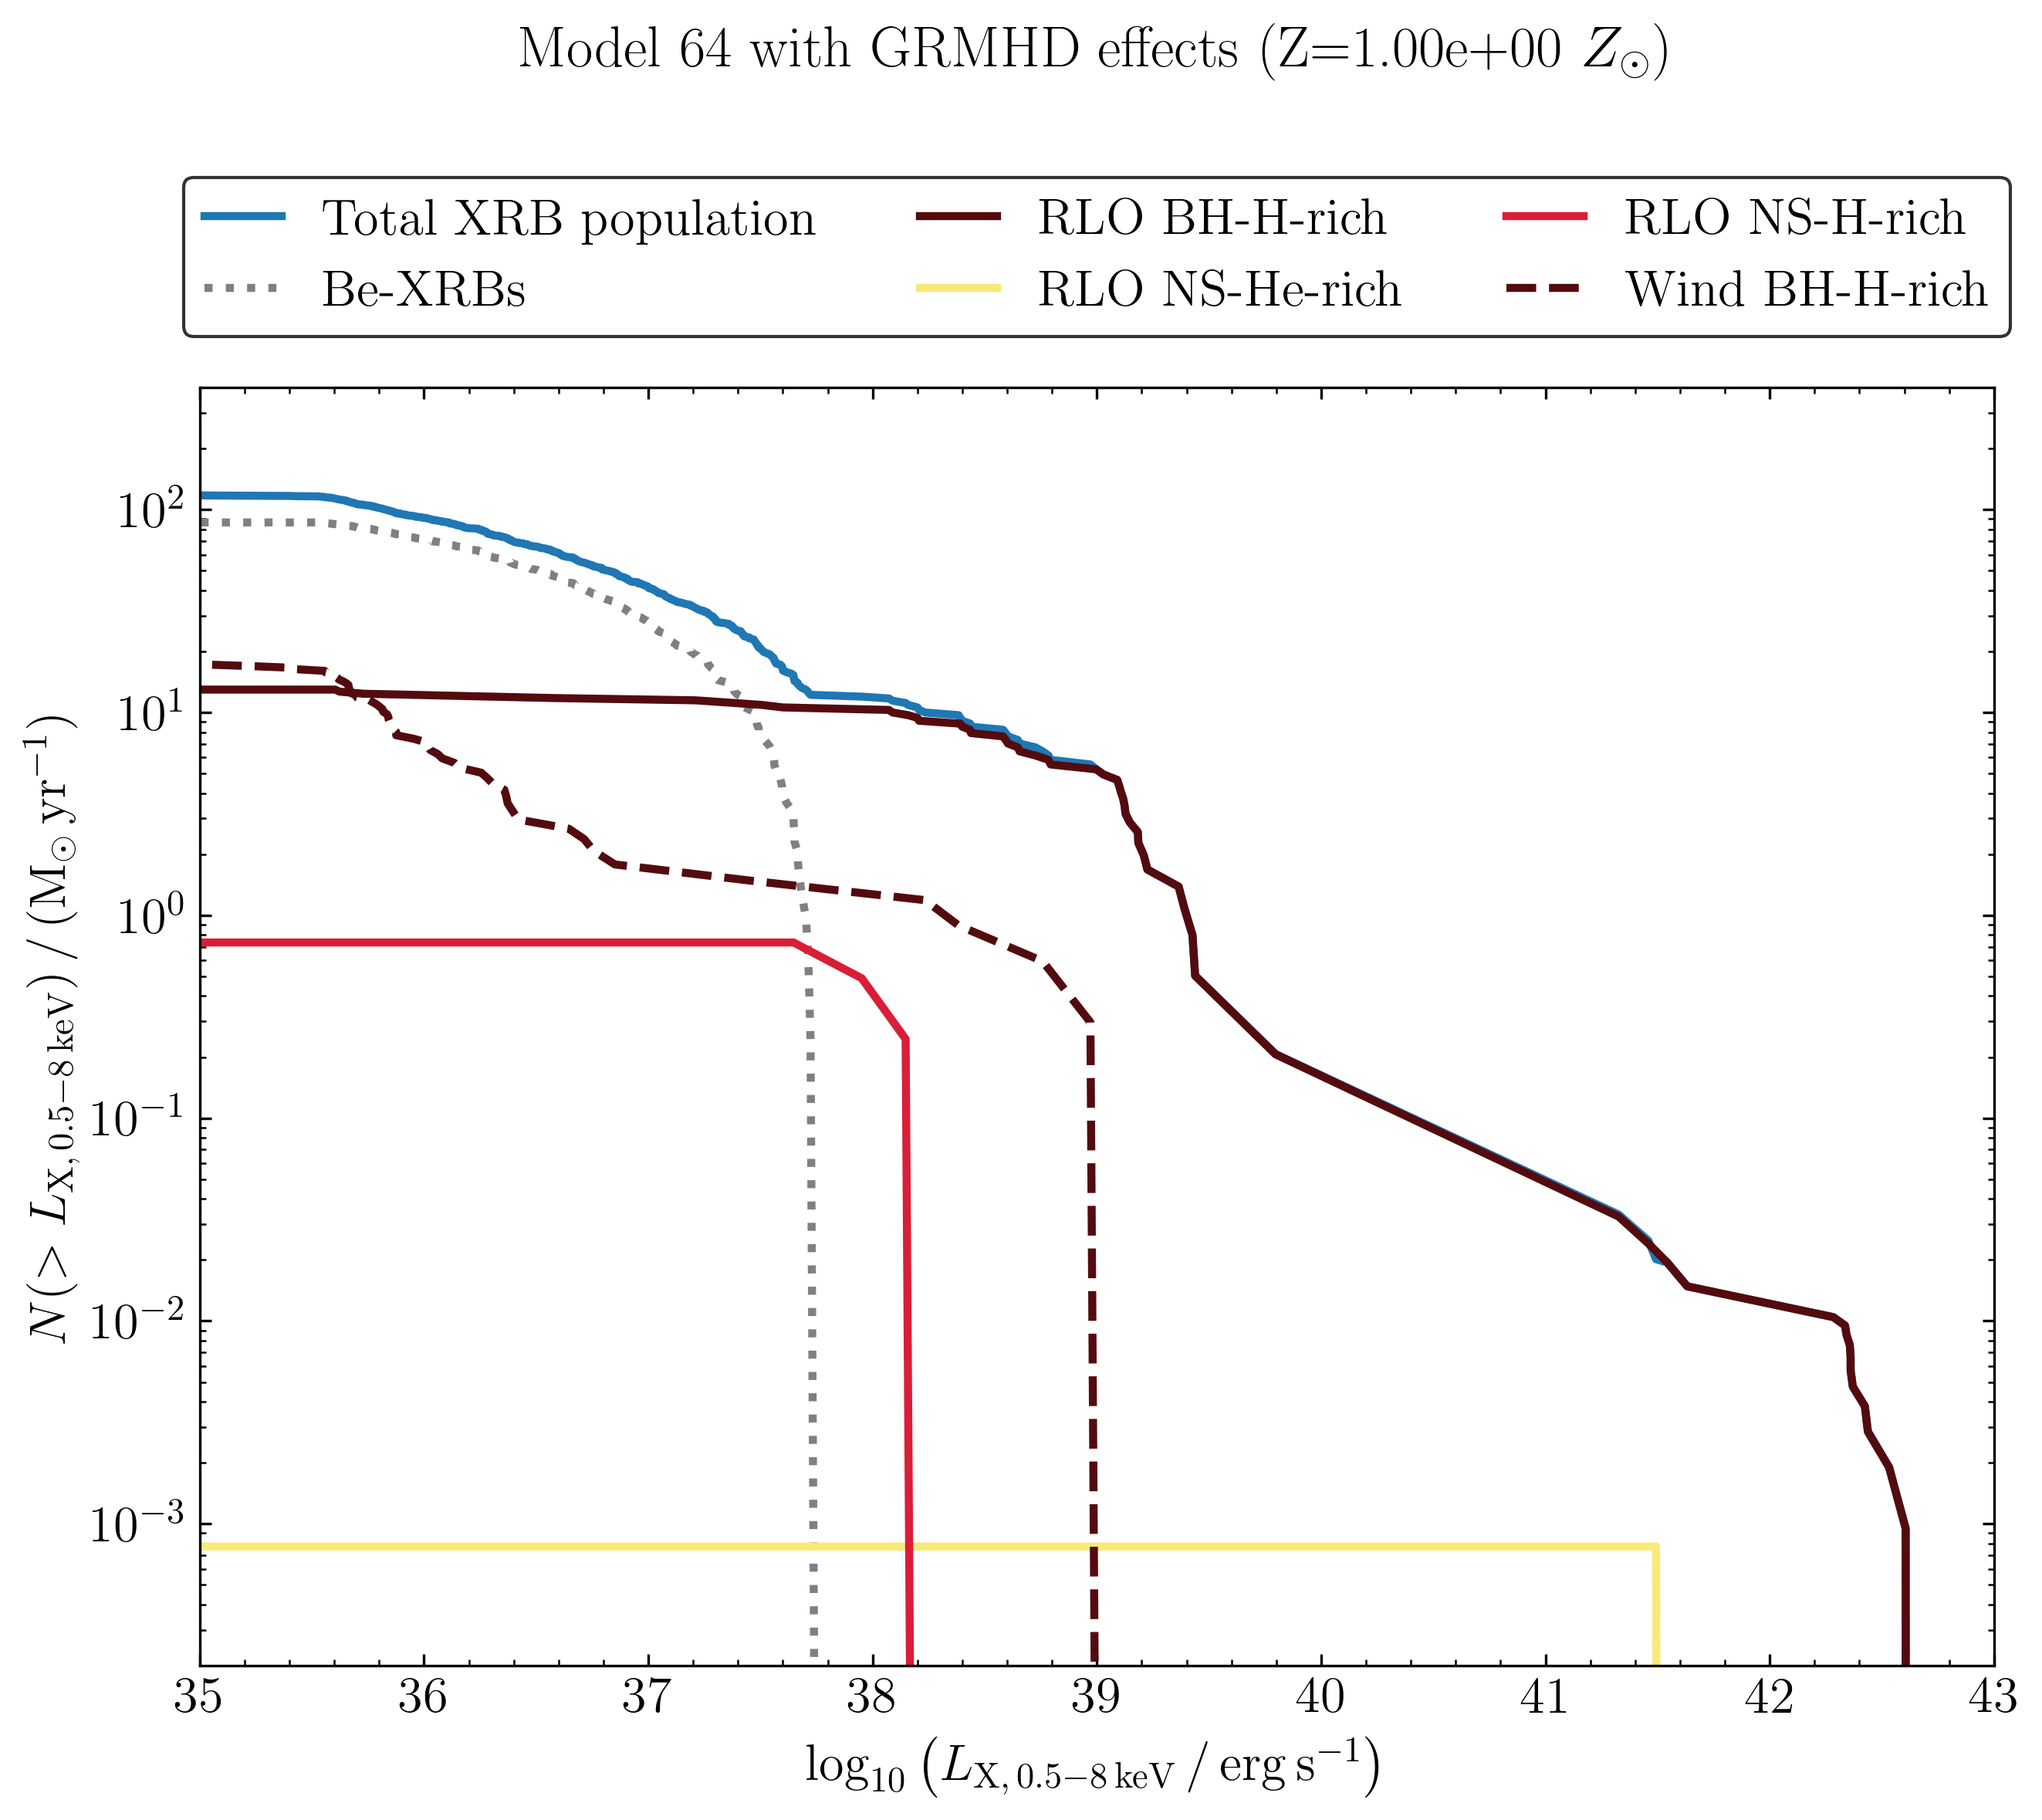

In [28]:
fig, ax =Plot_cumulative_XLF(Trans_Pop_64, Weights_64, title='Model 64 with GRMHD effects',linewidth=2.5)
fig.savefig('Pop_with_GRMHD/Best_Pop_with_GRMHD/Pop_64/XLF_GRMHD_64.png', dpi=300)
plt.show()